## Fig2

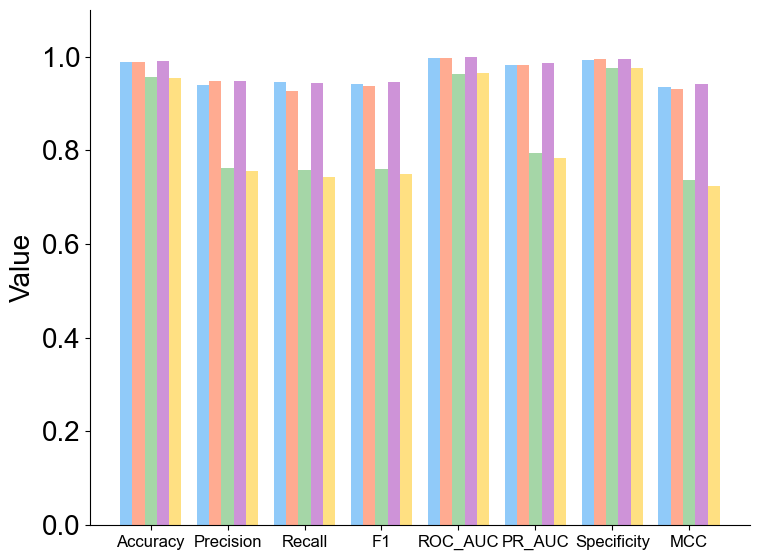


Average Metrics Across All Files:
----------------------------------------
Accuracy    : 0.9759
Precision   : 0.8708
Recall      : 0.8633
F1          : 0.8670
ROC_AUC     : 0.9848
PR_AUC      : 0.9056
Specificity : 0.9872
MCC         : 0.8538


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
from sklearn.metrics import (confusion_matrix, precision_recall_curve, auc,
                             accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, matthews_corrcoef)

font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf' 
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 20  # 期刊要求字体大小5-7pt
#plt.rcParams['font.size'] = 6  # 期刊要求字体大小5-7pt
# 计算指标函数
def compute_metrics(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp + 1e-6)
    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = auc(recall, precision)
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'ROC_AUC': roc_auc_score(y_true, y_prob),
        'PR_AUC': pr_auc,
        'Specificity': specificity,
        'MCC': matthews_corrcoef(y_true, y_pred)
    }

# 文件路径与标签
csv_files = [
    'a549/a549_801_pred.csv',
    'cd8t/cd8t_801_pred.csv',
    'hek293/hek293_801_pred.csv',
    'hela/hela_801_pred.csv',
    'molm/molm_801_pred.csv',

]
file_labels = [ 'A549', 'CD8T', 'HEK293', 'HeLa', 'MOLM13']

colors = ['#90CAF9', '#FFAB91', '#A5D6A7', '#CE93D8', '#FFE082']  # 蓝, 橙, 绿, 紫, 黄
#colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974']

# 计算所有指标
all_metrics = []
for file in csv_files:
    data = pd.read_csv(file)
    y_true = data['label'].values
    y_pred = data['predict'].values
    y_prob = data['predict_probs'].values
    metrics = compute_metrics(y_true, y_pred, y_prob)
    all_metrics.append(metrics)

# 准备绘图数据
metric_names = list(all_metrics[0].keys())
x = np.arange(len(metric_names))
bar_width = 0.8 / len(csv_files)

# 创建高质量图像
#fig, ax = plt.subplots(figsize=(6, 3))  # 7 in = 180 mm（期刊最大宽度）
fig, ax = plt.subplots(figsize=(8, 6))
# 绘图
for i in range(len(csv_files)):
    values = list(all_metrics[i].values())
    ax.bar(x + i * bar_width, values, bar_width, label=file_labels[i],
           color=colors[i])

# 图形美化
#ax.set_title('LAMAR-801: Performance across Different Training Sets', fontsize=7, pad=8)
#ax.set_xlabel('Metric', fontsize=6)
# 去掉上边框和右边框
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylabel('Value')
ax.set_ylim(0, 1.1)
ax.set_yticks(np.arange(0, 1.1, 0.2))
ax.set_xticks(x + bar_width * (len(csv_files)-1)/2)
ax.set_xticklabels(metric_names, ha='center',fontsize=12)

# 图例设置在图外右上角
#ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=6, frameon=False)
#ax.legend(loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.16),frameon=False)

# 自适应布局
fig.tight_layout()

# 保存图像为 PNG（期刊建议格式），600 dpi，防止文字裁剪
#plt.savefig('fig-1/Fig2A-1-1.png', dpi=600, bbox_inches='tight', format='png')
plt.show()

# 输出平均指标
print("\nAverage Metrics Across All Files:\n" + "-"*40)
for metric in metric_names:
    avg = np.mean([m[metric] for m in all_metrics])
    print(f"{metric:12s}: {avg:.4f}")

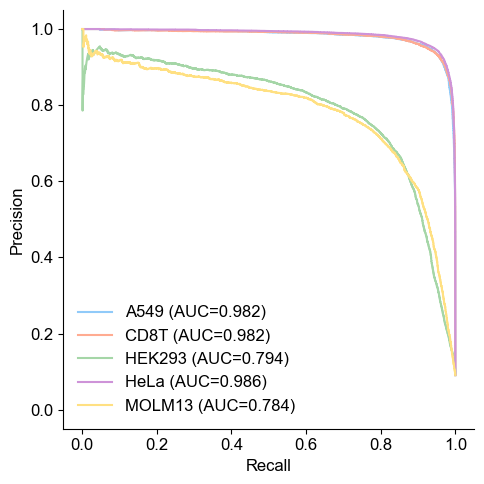

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
from sklearn.metrics import precision_recall_curve, auc

# 字体路径和设置
font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf' 
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12  # 期刊要求字体大小5-7pt

# 文件路径与标签
csv_files = [
    'a549/a549_801_pred.csv',
    'cd8t/cd8t_801_pred.csv',
    'hek293/hek293_801_pred.csv',
    'hela/hela_801_pred.csv',
    'molm/molm_801_pred.csv',
]
file_labels = ['A549', 'CD8T', 'HEK293', 'HeLa', 'MOLM13']

colors = ['#90CAF9', '#FFAB91', '#A5D6A7', '#CE93D8', '#FFE082']

plt.figure(figsize=(5, 5))  # 7 inch宽，4.5 inch高

for i, file in enumerate(csv_files):
    data = pd.read_csv(file)
    y_true = data['label'].values
    y_prob = data['predict_probs'].values
    
    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = auc(recall, precision)
    
    plt.plot(recall, precision, color=colors[i], lw=1.5, label=f'{file_labels[i]} (AUC={pr_auc:.3f})')

plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
#plt.title('Precision-Recall Curve for Five Cell Lines', fontsize=7, pad=8)
plt.legend(loc='lower left', fontsize=12, frameon=False)
#plt.grid(True, linestyle='--', alpha=0.3)
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('fig-1/fig2B-1-1.png', dpi=600, bbox_inches='tight', format='png')
plt.show()


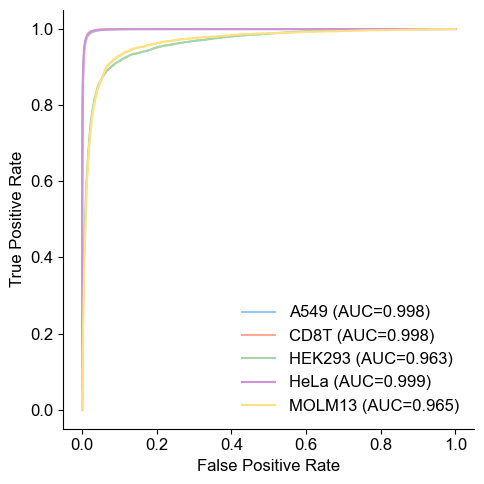

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score

# 字体路径和设置
font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf' 
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12  # 期刊要求字体大小5-7pt

# 文件路径与标签
csv_files = [
    'a549/a549_801_pred.csv',
    'cd8t/cd8t_801_pred.csv',
    'hek293/hek293_801_pred.csv',
    'hela/hela_801_pred.csv',
    'molm/molm_801_pred.csv',
]
file_labels = ['A549', 'CD8T', 'HEK293', 'HeLa', 'MOLM13']

colors = ['#90CAF9', '#FFAB91', '#A5D6A7', '#CE93D8', '#FFE082']

plt.figure(figsize=(5, 5)) 

for i, file in enumerate(csv_files):
    data = pd.read_csv(file)
    y_true = data['label'].values
    y_prob = data['predict_probs'].values
    
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = roc_auc_score(y_true, y_prob)
    
    plt.plot(fpr, tpr, color=colors[i], lw=1.5, label=f'{file_labels[i]} (AUC={roc_auc:.3f})')

# 画对角虚线 (随机分类线)
#plt.plot([0, 1], [0, 1], color='grey', lw=1, linestyle='--', alpha=0.7)

plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
#plt.title('ROC Curve for Five Cell Lines', fontsize=7, pad=8)
plt.legend(loc='lower right', fontsize=12, frameon=False)
#plt.grid(True, linestyle='--', alpha=0.3)
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('fig-1/fig2C-1-1.png', dpi=600, bbox_inches='tight', format='png')
plt.show()


PR-AUC for A549 model on A549: 0.982
PR-AUC for A549 model on CD8T: 0.978
PR-AUC for A549 model on HEK293: 0.878
PR-AUC for A549 model on HeLa: 0.973
PR-AUC for A549 model on MOLM13: 0.955
PR-AUC for CD8T model on A549: 0.980
PR-AUC for CD8T model on CD8T: 0.982
PR-AUC for CD8T model on HEK293: 0.845
PR-AUC for CD8T model on HeLa: 0.974
PR-AUC for CD8T model on MOLM13: 0.962
PR-AUC for HEK293 model on A549: 0.788
PR-AUC for HEK293 model on CD8T: 0.754
PR-AUC for HEK293 model on HEK293: 0.794
PR-AUC for HEK293 model on HeLa: 0.766
PR-AUC for HEK293 model on MOLM13: 0.756
PR-AUC for HeLa model on A549: 0.988
PR-AUC for HeLa model on CD8T: 0.986
PR-AUC for HeLa model on HEK293: 0.848
PR-AUC for HeLa model on HeLa: 0.986
PR-AUC for HeLa model on MOLM13: 0.969
PR-AUC for MOLM13 model on A549: 0.813
PR-AUC for MOLM13 model on CD8T: 0.788
PR-AUC for MOLM13 model on HEK293: 0.782
PR-AUC for MOLM13 model on HeLa: 0.793
PR-AUC for MOLM13 model on MOLM13: 0.784
Plot ready with new order: A549, CD

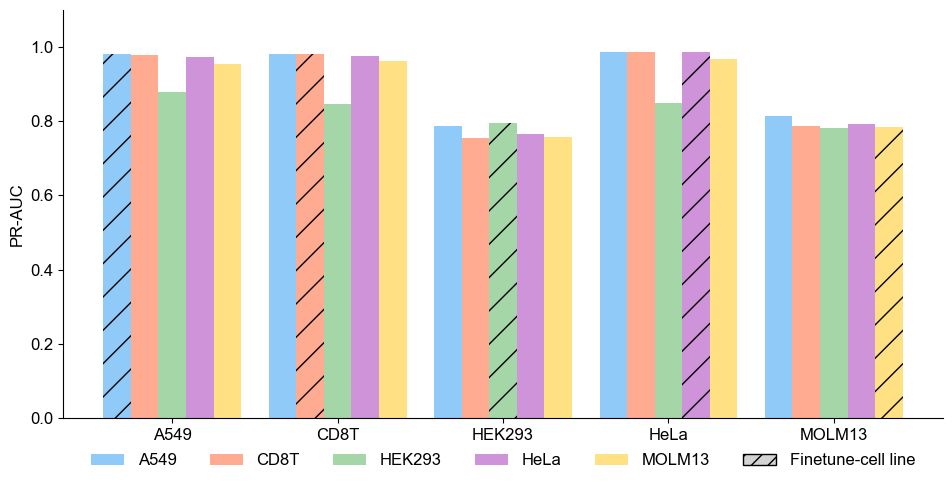

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, precision_recall_curve, auc, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, matthews_corrcoef
from matplotlib.patches import Patch
import matplotlib.font_manager as fm

# 字体路径和设置
font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf' 
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12  # 期刊要求字体大小5-7pt

# Define the compute_metrics function
def compute_metrics(y_true, y_pred, y_prob):
    try:
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        specificity = tn / (tn + fp + 1e-6)
        precision, recall, _ = precision_recall_curve(y_true, y_prob)
        pr_auc = auc(recall, precision)
        return {
            'accuracy': accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred, zero_division=0),
            'recall': recall_score(y_true, y_pred, zero_division=0),
            'f1': f1_score(y_true, y_pred, zero_division=0),
            'roc_auc': roc_auc_score(y_true, y_prob),
            'pr_auc': pr_auc,
            'specificity': specificity,
            'mcc': matthews_corrcoef(y_true, y_pred)
        }
    except Exception as e:
        print(f"Error computing metrics: {e}")
        return {'pr_auc': 0.0}  # Default value on error

# List of CSV files and corresponding group/target cell line names
csv_files = [
    'a549/a549_801_pred.csv',
    'a549/cd8t_801_pred.csv',
    'a549/hek293_801_pred.csv',
    'a549/hela_801_pred.csv',
    'a549/molm_801_pred.csv',
    'cd8t/a549_801_pred.csv',
    'cd8t/cd8t_801_pred.csv',
    'cd8t/hek293_801_pred.csv',
    'cd8t/hela_801_pred.csv',
    'cd8t/molm_801_pred.csv',
    'hek293/a549_801_pred.csv',
    'hek293/cd8t_801_pred.csv',
    'hek293/hek293_801_pred.csv',
    'hek293/hela_801_pred.csv',
    'hek293/molm_801_pred.csv',
    'hela/a549_801_pred.csv',
    'hela/cd8t_801_pred.csv',
    'hela/hek293_801_pred.csv',
    'hela/hela_801_pred.csv',
    'hela/molm_801_pred.csv',
    'molm/a549_801_pred.csv',
    'molm/cd8t_801_pred.csv',
    'molm/hek293_801_pred.csv',
    'molm/hela_801_pred.csv',
    'molm/molm_801_pred.csv',
]
groups = ['A549', 'A549', 'A549', 'A549', 'A549',
          'CD8T', 'CD8T', 'CD8T', 'CD8T', 'CD8T',
          'HEK293', 'HEK293', 'HEK293', 'HEK293', 'HEK293',
          'HeLa', 'HeLa', 'HeLa', 'HeLa', 'HeLa',
          'MOLM13', 'MOLM13', 'MOLM13', 'MOLM13', 'MOLM13',
         ]
target_cell_lines = ['A549', 'CD8T', 'HEK293', 'HeLa', 'MOLM13',
                     'A549', 'CD8T', 'HEK293', 'HeLa', 'MOLM13',
                     'A549', 'CD8T', 'HEK293', 'HeLa', 'MOLM13',
                     'A549', 'CD8T', 'HEK293', 'HeLa', 'MOLM13',
                     'A549', 'CD8T', 'HEK293', 'HeLa', 'MOLM13',
                    ]

# Compute PR-AUC for each file
pr_auc_values = []
for csv_file, group, target in zip(csv_files, groups, target_cell_lines):
    try:
        # Read CSV
        data = pd.read_csv(csv_file)
        
        # Verify required columns
        required_columns = ['label', 'predict', 'predict_probs']
        if not all(col in data.columns for col in required_columns):
            print(f"Error: {csv_file} missing required columns: {required_columns}")
            pr_auc_values.append(0.0)
            continue
        
        # Extract relevant columns
        y_true = data['label'].values
        y_pred = data['predict'].values
        y_prob = data['predict_probs'].values
        
        # Validate probabilities
        if not np.all((y_prob >= 0) & (y_prob <= 1)):
            print(f"Warning: {csv_file} contains invalid predict probs values")
            pr_auc_values.append(0.0)
            continue
        
        # Compute metrics
        metrics = compute_metrics(y_true, y_pred, y_prob)
        pr_auc_values.append(metrics['pr_auc'])
        print(f"PR-AUC for {group} model on {target}: {metrics['pr_auc']:.3f}")
    except FileNotFoundError:
        print(f"Error: File {csv_file} not found")
        pr_auc_values.append(0.0)
    except Exception as e:
        print(f"Error processing {csv_file}: {e}")
        pr_auc_values.append(0.0)

# 按新顺序调整模型组
unique_groups = ['A549', 'CD8T', 'HEK293', 'HeLa', 'MOLM13']
target_labels = ['A549', 'CD8T', 'HEK293', 'HeLa', 'MOLM13']

pr_auc_groups = [
    pr_auc_values[0:5],  
    pr_auc_values[5:10],  
    pr_auc_values[10:15], 
    pr_auc_values[15:20], 
    pr_auc_values[20:25]
]

colors = ['#90CAF9', '#FFAB91', '#A5D6A7', '#CE93D8', '#FFE082']  # 蓝, 橙, 绿, 紫, 黄
bar_width = 0.2
group_width = len(target_labels) * bar_width

x = np.arange(len(unique_groups)) * (group_width + 0.2)

plt.figure(figsize=(10, 5))

for i, target in enumerate(target_labels):
    values = [pr_auc_groups[g][i] for g in range(len(unique_groups))]
    bars = plt.bar(x + i * bar_width, values, bar_width, color=colors[i])
    
    # 只有模型组名称和目标名称相同的条形加斜线
    for g, bar in enumerate(bars):
        if target == unique_groups[g]:
            bar.set_hatch('/')

#plt.title('PR-AUC Comparison Across Cell Lines', fontsize=14, pad=15)
#plt.xlabel('Model', fontsize=6)
plt.ylabel('PR-AUC')
plt.gca().set_yticks(np.arange(0, 1.1, 0.2))
plt.ylim(0, max(1.1, max(pr_auc_values) + 0.05))
plt.xticks(x + group_width / 2 - bar_width / 2, unique_groups,fontsize=12)
#plt.grid(True, axis='y', linestyle='--', alpha=0.7)

# 普通颜色图例
legend_elements = [
    Patch(facecolor=colors[i], edgecolor='none', label=target_labels[i])
    for i in range(len(target_labels))
]

# 斜线图例（表示 fine-tune cell line）
legend_elements.append(
    Patch(facecolor='lightgray', edgecolor='black', hatch='//', label='Finetune-cell line')
)

# 在图下方添加图例
plt.legend(
    handles=legend_elements,
    loc='upper center',             # 图例在底部上方（靠近图底）
    bbox_to_anchor=(0.5, -0.05),    # x=0.5 居中，y=-0.15 表示在图外下方一点
    ncol=len(legend_elements),      # 水平排列
    frameon=False,                  # 去掉边框
    fontsize=12
)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

plt.savefig('fig-1/fig2D-1-2.png', dpi=600, bbox_inches='tight', format='png')
print("Plot ready with new order: A549, CD8T, HEK293, HELA, MOLM")

plt.show()


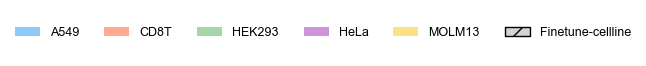

In [21]:
from matplotlib.patches import Patch

# 普通颜色图例
legend_elements = [
    Patch(facecolor=colors[i], edgecolor='none', label=target_labels[i])
    for i in range(len(target_labels))
]

# 斜线图例（用某个颜色底 + 斜线）
legend_elements.append(
    Patch(facecolor='lightgray', edgecolor='black', hatch='//', label='Finetune-cellline')
)

# 新建图例 figure
fig_legend = plt.figure(figsize=(6, 0.6))
plt.legend(
    handles=legend_elements,
    loc='center',
    ncol=len(legend_elements),
    frameon=False   # 去掉图例边框
)
plt.axis('off')

# 保存独立图例
fig_legend.savefig('fig/fig2D-legend.png', dpi=600, bbox_inches='tight', format='png')
plt.show()

## Fig3

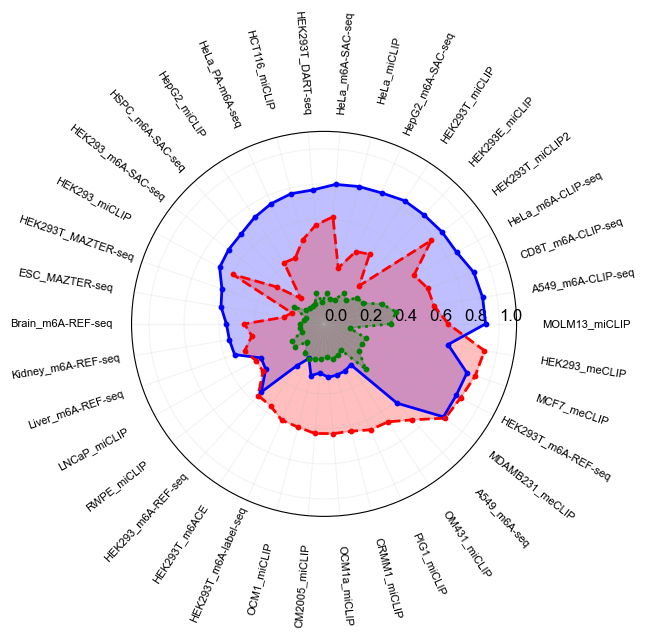

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import pi
import matplotlib.font_manager as fm
import matplotlib.patches as mpatches

font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf' 
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

# === 1. 文件路径 ===
file1 = '/work/home/rnasys/lidaoqian/LARMAR/output/test/predict/human/lamar801_cell5_atlas_a_predict_results.csv'
file2 = '/work/home/rnasys/lidaoqian/M6A_Model/deepSRAMP/deepSRAMP/test-38/human/atlas_human_full_400_a549_single_a.csv'
file3 = '/work/home/rnasys/lidaoqian/M6A_Model/deepSRAMP/deepSRAMP/test-36/human/atlas_human_full_400_a549_dp_single_a.csv'

# === 2. 读取并标记来源 ===
df1 = pd.read_csv(file1)
df1['File'] = 'LAMAR-M6A'

df2 = pd.read_csv(file2)
df2['File'] = 'deepSRAMP'

df3 = pd.read_csv(file3)
df3['File'] = 'DeepPromise'

# === 3. 统一处理 Class 字段 ===
#df1['Class'] = df1['Class'].str.replace('CM2005_pred.csv', 'CM2005_miCLIP')
df1['Class'] = df1['Class'].str.replace('CM2005.1_miCLIP', 'CM2005_miCLIP')
df1['Class'] = df1['Class'].str.replace('A549_m6A-seq_with_improved_protocol', 'A549_m6A-seq')
# 处理 df2 的 Class 列
df2['Class'] = df2['Class'].str.replace(' ', '_')  # 将空格替换为下划线
df2['Class'] = df2['Class'].str.rstrip('_')        # 去除末尾的下划线
df2['Class'] = df2['Class'].str.replace('CM2005.1_miCLIP', 'CM2005_miCLIP')
df2['Class'] = df2['Class'].str.replace('A549_m6A-seq_with_improved_protocol', 'A549_m6A-seq')
# 处理 df3 的 Class 列
df3['Class'] = df3['Class'].str.replace(' ', '_')  # 将空格替换为下划线
df3['Class'] = df3['Class'].str.rstrip('_')        # 去除末尾的下划线
df3['Class'] = df3['Class'].str.replace('CM2005.1_miCLIP', 'CM2005_miCLIP')
df3['Class'] = df3['Class'].str.replace('A549_m6A-seq_with_improved_protocol', 'A549_m6A-seq')

# === 4. 合并数据 ===
df_combined = pd.concat([df1, df2, df3])

# === 5. 准备对比数据框 ===
metric = 'PR_AUC'
tools = ['LAMAR-M6A', 'deepSRAMP', 'DeepPromise']

comparison_df = pd.DataFrame({'Class': df_combined['Class'].unique()})

for tool in tools:
    comparison_df[tool] = comparison_df['Class'].apply(
        lambda x: df_combined[(df_combined['Class'] == x) & (df_combined['File'] == tool)][metric].values[0]
    )


# === 6. 排序逻辑：按 LARMAR 优势排序 ===
comparison_df['Difference'] = comparison_df['LAMAR-M6A'] - comparison_df[[t for t in tools if t != 'LAMAR-M6A']].max(axis=1)
better_larmar = comparison_df[comparison_df['Difference'] > 0].sort_values('LAMAR-M6A', ascending=False)
others_better = comparison_df[comparison_df['Difference'] <= 0].sort_values(by=tools[1:], ascending=True)
comparison_df = pd.concat([better_larmar, others_better])

# === 7. 雷达图绘制 ===
classes = comparison_df['Class'].tolist()
N = len(classes)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111, polar=True)

#plt.title('M6A-Atlas Human Dataset', fontsize=12, pad=80)

# 每个模型绘图样式
style_dict = {
    'LAMAR-M6A': {'color': 'b', 'linestyle': 'solid'},
    'deepSRAMP': {'color': 'r', 'linestyle': 'dashed'},
    'DeepPromise': {'color': 'g', 'linestyle': 'dotted'}
}

# 绘图
for tool in tools:
    values = [comparison_df.loc[comparison_df['Class'] == c, tool].values[0] for c in classes]
    values += values[:1]
    ax.fill(angles, values, alpha=0.25, color=style_dict[tool]['color'], label=tool)
    ax.plot(angles, values, color=style_dict[tool]['color'], linestyle=style_dict[tool]['linestyle'], linewidth=2)
    for i, angle in enumerate(angles[:-1]):
        ax.scatter(angle, values[i], color=style_dict[tool]['color'], s=10, zorder=5)

# === 美化：圆圈标签 & 类别标签 ===
y_ticks = np.linspace(0, 1, 6)
ax.set_rgrids(y_ticks, labels=[f'{y:.1f}' for y in y_ticks], angle=0, fontsize=12)

ax.set_xticks(angles[:-1])
ax.set_xticklabels([])
ax.yaxis.grid(alpha=0.15)
ax.xaxis.grid(alpha=0.15)
ax.set_ylim(0, 1.1)

for i, angle in enumerate(angles[:-1]):
    rotation = np.rad2deg(angle)
    if 90 < rotation <= 270:
        rotation += 180
    ax.text(angle, 1.50, classes[i], ha='center', va='center', 
            rotation=rotation, rotation_mode='anchor', fontsize=8)

# === 图例放到底部中间，三列展示 ===
handles = [
    mpatches.Patch(color='none', label='PR-AUC: '),  # 说明文字行（无颜色）
    plt.Line2D([0], [0], color='b', lw=1.5, linestyle='solid', label='LAMAR-M6A'),
    plt.Line2D([0], [0], color='r', lw=1.5, linestyle='dashed', label='deepSRAMP'),
    plt.Line2D([0], [0], color='g', lw=1.5, linestyle='dotted', label='DeepPromise'),
]

# 设置 legend 到下方中间，三列展示

plt.savefig('/work/home/rnasys/lidaoqian/M6A_Model/deepSRAMP/deepSRAMP/test-38/human/fig3A-1.png', dpi=600, bbox_inches='tight', format='png')
plt.show()
#comparison_df.to_csv('fig/Fig3A_PR_AUC_comparison.csv', index=False)

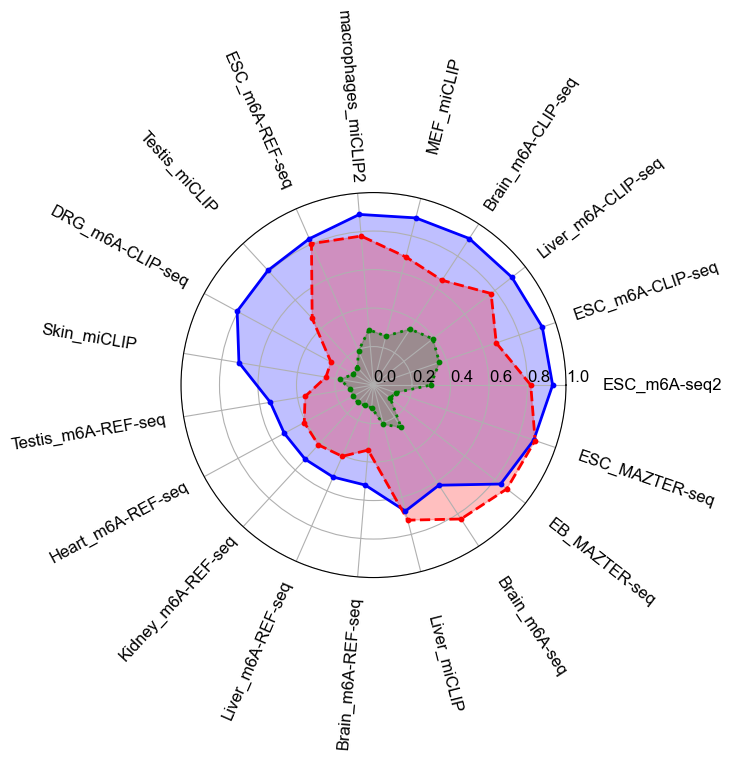

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import pi
import matplotlib.font_manager as fm
import matplotlib.patches as mpatches

font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf' 
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12 

# === 1. 文件路径 ===
file1 = '/work/home/rnasys/lidaoqian/LARMAR/output/test/predict/mouse/lamar801_cell5_atlas_a_predict_results.csv'
file2 = '/work/home/rnasys/lidaoqian/M6A_Model/deepSRAMP/deepSRAMP/test-38/mouse/atlas_mouse_full_400_a549_single_a_merged.csv'
file3 = '/work/home/rnasys/lidaoqian/M6A_Model/deepSRAMP/deepSRAMP/test-36/mouse/atlas_mouse_full_400_a549_dp_a_merged.csv'

# === 2. 读取并标记来源 ===
df1 = pd.read_csv(file1)
df1['File'] = 'LAMAR-M6A'

df2 = pd.read_csv(file2)
df2['File'] = 'deepSRAMP'

df3 = pd.read_csv(file3)
df3['File'] = 'DeepPromise'

# === 3. 统一处理 Class 字段 ===
df1['Class'] = df1['Class'].str.replace('Mouse_Embryonic_Fibroblasts_miCLIP', 'MEF_miCLIP')
df1['Class'] = df1['Class'].str.replace('Brain_m6A-seq_with_improved_protocol', 'Brain_m6A-seq')

# 处理 df2 的 Class 列
df2['Class'] = df2['Class'].str.replace(' ', '_')  # 将空格替换为下划线
df2['Class'] = df2['Class'].str.rstrip('_')        # 去除末尾的下划线
df2['Class'] = df2['Class'].str.replace('Brain_m6A-seq_with_improved_protocol', 'Brain_m6A-seq')
df2['Class'] = df2['Class'].str.replace('Mouse_Embryonic_Fibroblasts_(MEFs)_miCLIP', 'MEF_miCLIP')
df2['Class'] = df2['Class'].str.replace('dorsal_root_ganglion?(DRG)_m6A-CLIP-seq', 'DRG_m6A-CLIP-seq')
# 处理 df3 的 Class 列
df3['Class'] = df3['Class'].str.replace(' ', '_')  # 将空格替换为下划线
df3['Class'] = df3['Class'].str.rstrip('_')        # 去除末尾的下划线
df3['Class'] = df3['Class'].str.replace('Brain_m6A-seq_with_improved_protocol', 'Brain_m6A-seq')
df3['Class'] = df3['Class'].str.replace('Mouse_Embryonic_Fibroblasts_(MEFs)_miCLIP', 'MEF_miCLIP')
df3['Class'] = df3['Class'].str.replace('dorsal_root_ganglion?(DRG)_m6A-CLIP-seq', 'DRG_m6A-CLIP-seq')
# === 4. 合并数据 ===
df_combined = pd.concat([df1, df2, df3])

# === 5. 准备对比数据框 ===
metric = 'PR_AUC'
tools = ['LAMAR-M6A', 'deepSRAMP', 'DeepPromise']

comparison_df = pd.DataFrame({'Class': df_combined['Class'].unique()})

for tool in tools:
    comparison_df[tool] = comparison_df['Class'].apply(
        lambda x: df_combined[(df_combined['Class'] == x) & (df_combined['File'] == tool)][metric].values[0]
    )


# === 6. 排序逻辑：按 LARMAR 优势排序 ===
comparison_df['Difference'] = comparison_df['LAMAR-M6A'] - comparison_df[[t for t in tools if t != 'LAMAR-M6A']].max(axis=1)
better_larmar = comparison_df[comparison_df['Difference'] > 0].sort_values('LAMAR-M6A', ascending=False)
others_better = comparison_df[comparison_df['Difference'] <= 0].sort_values(by=tools[1:], ascending=True)
comparison_df = pd.concat([better_larmar, others_better])

# === 7. 雷达图绘制 ===
classes = comparison_df['Class'].tolist()
N = len(classes)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111, polar=True)

#plt.title('M6A-Atlas Mouse Dataset', fontsize=12, pad=90)

# 每个模型绘图样式
style_dict = {
    'LAMAR-M6A': {'color': 'b', 'linestyle': 'solid'},
    'deepSRAMP': {'color': 'r', 'linestyle': 'dashed'},
    'DeepPromise': {'color': 'g', 'linestyle': 'dotted'}
}

# 绘图
for tool in tools:
    values = [comparison_df.loc[comparison_df['Class'] == c, tool].values[0] for c in classes]
    values += values[:1]
    ax.fill(angles, values, alpha=0.25, color=style_dict[tool]['color'], label=tool)
    ax.plot(angles, values, color=style_dict[tool]['color'], linestyle=style_dict[tool]['linestyle'], linewidth=2)
    for i, angle in enumerate(angles[:-1]):
        ax.scatter(angle, values[i], color=style_dict[tool]['color'], s=10, zorder=5)

# === 美化：圆圈标签 & 类别标签 ===
y_ticks = np.linspace(0, 1, 6)
ax.set_rgrids(y_ticks, labels=[f'{y:.1f}' for y in y_ticks], angle=0, fontsize=12)

ax.set_xticks(angles[:-1])
ax.set_xticklabels([])

ax.set_ylim(0, 1.0)

for i, angle in enumerate(angles[:-1]):
    rotation = np.rad2deg(angle)
    if 90 < rotation <= 270:
        rotation += 180
    ax.text(angle, 1.50, classes[i], ha='center', va='center', 
            rotation=rotation, rotation_mode='anchor', fontsize=12)

# === 图例放到底部中间，三列展示 ===
handles = [
    mpatches.Patch(color='none', label='PR-AUC: '),  # 说明文字行（无颜色）
    plt.Line2D([0], [0], color='b', lw=1.5, linestyle='solid', label='LAMAR-M6A'),
    plt.Line2D([0], [0], color='r', lw=1.5, linestyle='dashed', label='deepSRAMP'),
    plt.Line2D([0], [0], color='g', lw=1.5, linestyle='dotted', label='DeepPromise'),
]

# 设置 legend 到下方中间，三列展示

plt.savefig('fig-1/fig3B-1.png', dpi=600, bbox_inches='tight', format='png')
plt.show()
#comparison_df.to_csv('fig/Fig3B_PR_AUC_comparison.csv', index=False)

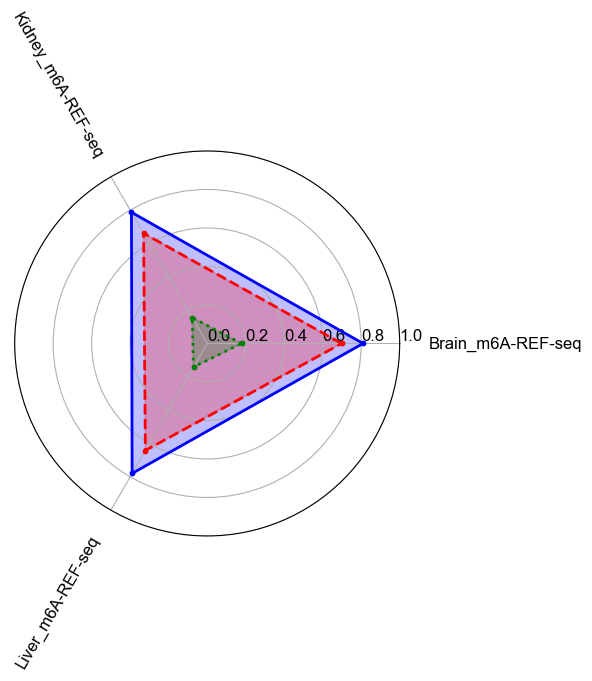

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import pi
import matplotlib.font_manager as fm
import matplotlib.patches as mpatches

font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf' 
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12 

# === 1. 文件路径 ===
file1 = '/work/home/rnasys/lidaoqian/LARMAR/output/test/predict/rat/lamar801_cell5_atlas_a_predict_results.csv'
file2 = '/work/home/rnasys/lidaoqian/M6A_Model/deepSRAMP/deepSRAMP/test-38/rat/atlas_rat_full_400_a549_single_a.csv'
file3 = '/work/home/rnasys/lidaoqian/M6A_Model/deepSRAMP/deepSRAMP/test-36/rat/atlas_rat_full_400_a549_dp_a.csv'

# === 2. 读取并标记来源 ===
df1 = pd.read_csv(file1)
df1['File'] = 'LAMAR-M6A'

df2 = pd.read_csv(file2)
df2['File'] = 'deepSRAMP'

df3 = pd.read_csv(file3)
df3['File'] = 'DeepPromise'

# === 3. 统一处理 Class 字段 ===

# === 4. 合并数据 ===
df_combined = pd.concat([df1, df2, df3])

# === 5. 准备对比数据框 ===
metric = 'PR_AUC'
tools = ['LAMAR-M6A', 'deepSRAMP', 'DeepPromise']

comparison_df = pd.DataFrame({'Class': df_combined['Class'].unique()})

for tool in tools:
    comparison_df[tool] = comparison_df['Class'].apply(
        lambda x: df_combined[(df_combined['Class'] == x) & (df_combined['File'] == tool)][metric].values[0]
    )


# === 6. 排序逻辑：按 LARMAR 优势排序 ===
comparison_df['Difference'] = comparison_df['LAMAR-M6A'] - comparison_df[[t for t in tools if t != 'LAMAR-M6A']].max(axis=1)
better_larmar = comparison_df[comparison_df['Difference'] > 0].sort_values('LAMAR-M6A', ascending=False)
others_better = comparison_df[comparison_df['Difference'] <= 0].sort_values(by=tools[1:], ascending=True)
comparison_df = pd.concat([better_larmar, others_better])

# === 7. 雷达图绘制 ===
classes = comparison_df['Class'].tolist()
N = len(classes)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111, polar=True)

#plt.title('M6A-Atlas Rat Dataset', fontsize=12, pad=80)

# 每个模型绘图样式
style_dict = {
    'LAMAR-M6A': {'color': 'b', 'linestyle': 'solid'},
    'deepSRAMP': {'color': 'r', 'linestyle': 'dashed'},
    'DeepPromise': {'color': 'g', 'linestyle': 'dotted'}
}

# 绘图
for tool in tools:
    values = [comparison_df.loc[comparison_df['Class'] == c, tool].values[0] for c in classes]
    values += values[:1]
    ax.fill(angles, values, alpha=0.25, color=style_dict[tool]['color'], label=tool)
    ax.plot(angles, values, color=style_dict[tool]['color'], linestyle=style_dict[tool]['linestyle'], linewidth=2)
    for i, angle in enumerate(angles[:-1]):
        ax.scatter(angle, values[i], color=style_dict[tool]['color'], s=10, zorder=5)

# === 美化：圆圈标签 & 类别标签 ===
y_ticks = np.linspace(0, 1, 6)
ax.set_rgrids(y_ticks, labels=[f'{y:.1f}' for y in y_ticks], angle=0, fontsize=12)

ax.set_xticks(angles[:-1])
ax.set_xticklabels([])

ax.set_ylim(0, 1.0)

for i, angle in enumerate(angles[:-1]):
    rotation = np.rad2deg(angle)
    if 90 < rotation <= 270:
        rotation += 180
    ax.text(angle, 1.55, classes[i], ha='center', va='center', 
            rotation=rotation, rotation_mode='anchor', fontsize=12)

# === 图例放到底部中间，三列展示 ===
handles = [
    mpatches.Patch(color='none', label='PR-AUC: '),  # 说明文字行（无颜色）
    plt.Line2D([0], [0], color='b', lw=1.5, linestyle='solid', label='LAMAR-M6A'),
    plt.Line2D([0], [0], color='g', lw=1.5, linestyle='dotted', label='DeepPromise'),
    plt.Line2D([0], [0], color='r', lw=1.5, linestyle='dashed', label='deepSRAMP'),

]

# 设置 legend 到下方中间，三列展示

plt.savefig('fig-1/fig3C-1.png', dpi=600, bbox_inches='tight', format='png')
plt.show()
#comparison_df.to_csv('fig/Fig3C_PR_AUC_comparison.csv', index=False)

##  Fig3-ppt

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import pi
import matplotlib.font_manager as fm
import matplotlib.patches as mpatches

font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf' 
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 10

# === 1. 文件路径 ===
file1 = '/work/home/rnasys/lidaoqian/LARMAR/output/test/predict/human/lamar801_cell5_atlas_a_predict_results.csv'
file2 = '/work/home/rnasys/lidaoqian/deepSRAMP/deepSRAMP/test-38/human/atlas_human_full_400_a549_single_a.csv'
file3 = '/work/home/rnasys/lidaoqian/deepSRAMP/deepSRAMP/test-36/human/atlas_human_full_400_a549_dp_single_a.csv'

# === 2. 读取并标记来源 ===
df1 = pd.read_csv(file1)
df1['File'] = 'LAMAR-M6A'

df2 = pd.read_csv(file2)
df2['File'] = 'deepSRAMP'

df3 = pd.read_csv(file3)
df3['File'] = 'DeepPromise'

# === 3. 统一处理 Class 字段 ===
#df1['Class'] = df1['Class'].str.replace('CM2005_pred.csv', 'CM2005_miCLIP')
df1['Class'] = df1['Class'].str.replace('CM2005.1_miCLIP', 'CM2005_miCLIP')
df1['Class'] = df1['Class'].str.replace('A549_m6A-seq_with_improved_protocol', 'A549_m6A-seq')
# 处理 df2 的 Class 列
df2['Class'] = df2['Class'].str.replace(' ', '_')  # 将空格替换为下划线
df2['Class'] = df2['Class'].str.rstrip('_')        # 去除末尾的下划线
df2['Class'] = df2['Class'].str.replace('CM2005.1_miCLIP', 'CM2005_miCLIP')
df2['Class'] = df2['Class'].str.replace('A549_m6A-seq_with_improved_protocol', 'A549_m6A-seq')
# 处理 df3 的 Class 列
df3['Class'] = df3['Class'].str.replace(' ', '_')  # 将空格替换为下划线
df3['Class'] = df3['Class'].str.rstrip('_')        # 去除末尾的下划线
df3['Class'] = df3['Class'].str.replace('CM2005.1_miCLIP', 'CM2005_miCLIP')
df3['Class'] = df3['Class'].str.replace('A549_m6A-seq_with_improved_protocol', 'A549_m6A-seq')

# === 4. 合并数据 ===
df_combined = pd.concat([df1, df2, df3])

# === 5. 准备对比数据框 ===
metric = 'PR_AUC'
tools = ['LAMAR-M6A', 'deepSRAMP', 'DeepPromise']

comparison_df = pd.DataFrame({'Class': df_combined['Class'].unique()})

for tool in tools:
    comparison_df[tool] = comparison_df['Class'].apply(
        lambda x: df_combined[(df_combined['Class'] == x) & (df_combined['File'] == tool)][metric].values[0]
    )


# === 6. 排序逻辑：按 LARMAR 优势排序 ===
comparison_df['Difference'] = comparison_df['LAMAR-M6A'] - comparison_df[[t for t in tools if t != 'LAMAR-M6A']].max(axis=1)
better_larmar = comparison_df[comparison_df['Difference'] > 0].sort_values('LAMAR-M6A', ascending=False)
others_better = comparison_df[comparison_df['Difference'] <= 0].sort_values(by=tools[1:], ascending=True)
comparison_df = pd.concat([better_larmar, others_better])

# === 7. 雷达图绘制 ===
classes = comparison_df['Class'].tolist()
N = len(classes)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, polar=True)

#plt.title('M6A-Atlas Human Dataset', fontsize=6, pad=80)

# 每个模型绘图样式
style_dict = {
    'LAMAR-M6A': {'color': 'b', 'linestyle': 'solid'},
    'deepSRAMP': {'color': 'r', 'linestyle': 'dashed'},
    'DeepPromise': {'color': 'g', 'linestyle': 'dotted'}
}

# 绘图
for tool in tools:
    values = [comparison_df.loc[comparison_df['Class'] == c, tool].values[0] for c in classes]
    values += values[:1]
    ax.fill(angles, values, alpha=0.25, color=style_dict[tool]['color'], label=tool)
    ax.plot(angles, values, color=style_dict[tool]['color'], linestyle=style_dict[tool]['linestyle'], linewidth=2)
    for i, angle in enumerate(angles[:-1]):
        ax.scatter(angle, values[i], color=style_dict[tool]['color'], s=10, zorder=5)

# === 美化：圆圈标签 & 类别标签 ===
y_ticks = np.linspace(0, 1, 6)
ax.set_rgrids(y_ticks, labels=[f'{y:.1f}' for y in y_ticks], angle=0)

ax.set_xticks(angles[:-1])
ax.set_xticklabels([])

ax.set_ylim(0, 1.7)

for i, angle in enumerate(angles[:-1]):
    rotation = np.rad2deg(angle)
    if 90 < rotation <= 270:
        rotation += 180
    ax.text(
        angle, 1.6, classes[i],
        ha='center', va='center',
        rotation=rotation, rotation_mode='anchor',
        fontsize=8  # 类别字体变小
    )

# === 图例放到底部中间，三列展示 ===
handles = [
    mpatches.Patch(color='none', label='PR-AUC: '),  # 说明文字行（无颜色）
    plt.Line2D([0], [0], color='b', lw=1.5, linestyle='solid', label='LAMAR-M6A'),
    plt.Line2D([0], [0], color='r', lw=1.5, linestyle='dashed', label='deepSRAMP'),
    plt.Line2D([0], [0], color='g', lw=1.5, linestyle='dotted', label='DeepPromise'),
]

# 设置 legend 到下方中间，三列展示
'''
fig.subplots_adjust(bottom=0.25)  # 留出底部空间
legend = ax.legend(
    handles=handles,
    loc='lower center', bbox_to_anchor=(0.5, -0.55),
    ncol=4, frameon=False,
    columnspacing=1.5, handlelength=2, handletextpad=1.2
)
'''
plt.savefig('/work/home/rnasys/lidaoqian/rnarsareg/generation_output/moderna/motif/plot/fig3A-1-2.png', dpi=600, bbox_inches='tight', format='png')
plt.show()
#comparison_df.to_csv('fig/Fig3A_PR_AUC_comparison.csv', index=False)

FileNotFoundError: [Errno 2] No such file or directory: '/work/home/rnasys/lidaoqian/deepSRAMP/deepSRAMP/test-38/human/atlas_human_full_400_a549_single_a.csv'

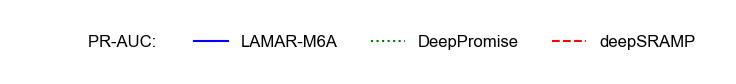

In [35]:
# ---------- 单独保存图例 ----------
legend_fig = plt.figure(figsize=(8, 1))   # 宽 3.5 in，高 0.8 in，可按需要调
legend_ax  = legend_fig.add_subplot(111)
legend_ax.axis('off')                         # 去掉坐标轴

legend = legend_ax.legend(
    handles=handles,
    loc='center',
    ncol=4,
    fontsize=12,
    frameon=False
)

legend_fig.tight_layout()
legend_fig.savefig('fig-1/fig3A-1_legend.png', dpi=600, bbox_inches='tight')
plt.show()

## Fig4

In [36]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.font_manager as fm
import os

# 字体设置（Arial，适配期刊）
font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

# 输入文件路径
csv_file = "/work/home/rnasys/lidaoqian/LARMAR/output/test/mutation/cell5_mutated_sequences_801_label1_100_predict_linear.csv"
df = pd.read_csv(csv_file)

# 检查必要列
required_columns = ['seq', 'predict_probs', 'is_original', 'original_seq', 'position', 'mutated_base']
if not all(col in df.columns for col in required_columns):
    raise ValueError(f"CSV 文件必须包含以下列：{', '.join(required_columns)}")

# 提取原始序列
original_df = df[df['is_original'] == 1].copy()
if original_df.empty:
    raise ValueError("未找到原始序列（is_original == 1）")

print(f"共分析 {len(original_df)} 条原始序列")

# 计算 Delta_pred_prob
original_probs = dict(zip(original_df['original_seq'], original_df['predict_probs']))
def calculate_delta_prob(row):
    if row['is_original'] == 1:
        return 0
    return row['predict_probs'] - original_probs.get(row['original_seq'], 0)
df['Delta_pred_prob'] = df.apply(calculate_delta_prob, axis=1)

# 提取突变数据并整理
mutation_df = df[(df['is_original'] == 0) & (df['Delta_pred_prob'].notnull())].copy()
mutation_df['position'] = mutation_df['position'].astype(int) - 1  # 调整为0-based

# 聚合数据
pivot_table = mutation_df.pivot_table(
    values='Delta_pred_prob',
    index='mutated_base',
    columns='position',
    aggfunc='mean'
)

# === 分段参数 ===
segment_size = 91
positions = pivot_table.columns
segments = [positions[i:i + segment_size] for i in range(0, len(positions), segment_size)]
n_segments = len(segments)

# === 全局颜色范围 ===
vmin, vmax = pivot_table.min().min(), pivot_table.max().max()
v_bound = max(abs(vmin), abs(vmax)) if vmin is not None else 1
vmin, vmax = -v_bound, v_bound

# === 图像参数 ===
fixed_width = 10
segment_height = 0.5    # 每段热图高度
gap_height = 0.3        # 每段之间间隙
dpi = 600
fig_height = n_segments * (segment_height + gap_height)+0.5

# === 创建图像 ===
fig = plt.figure(figsize=(fixed_width, fig_height), dpi=dpi)

for i, segment in enumerate(segments):
    sub_pivot = pivot_table[segment]

    # 位置换算：从上往下排布
    total_height = fig_height
    h = segment_height / total_height
    g = gap_height / total_height
    bottom = 1.0 - (i + 1) * h - i * g


    # 创建主热图轴
    ax = fig.add_axes([0.05, bottom, 0.8, h])
    
    # 仅最后一段添加颜色条
# 添加颜色条
    if i == n_segments - 1:
        cbar_bottom = bottom
        cbar_height = h
        cbar_left = 0.87
        cbar_width = 0.02
        cax = fig.add_axes([cbar_left, cbar_bottom, cbar_width, cbar_height])
    else:
        cax = None


    sns.heatmap(
        sub_pivot,
        #cmap='RdBu_r',
        #cmap='coolwarm',
        cmap='seismic',
        center=0,
        vmin=vmin,  # 统一颜色范围
        vmax=vmax,
        cbar_ax=cax if cax else None,
        cbar=i == n_segments - 1,  # 仅最后一个热图显示颜色条
        ax=ax,
        linewidths=0.5,
        annot=False,
        #square=True  # 强制格子为正方形
    )
    # 设置标题和Y轴标签
    #ax.set_title(f'Mutation Effect (Positions {segment[0]}-{segment[-1]})')
    ax.set_ylabel('Mutated Base')
    ax.tick_params(axis='y', rotation=0, labelleft=True)
    
    # 隐藏 X 轴刻度标签和刻度线
    #ax.set_xticks([])  # 移除 X 轴刻度
    ax.set_xlabel('')  # 确保无 X 轴标签
    ax.set_frame_on(False)

# === 保存图像和数据 ===
os.makedirs("fig-1", exist_ok=True)
fig.savefig("fig-1/fig4SA.png", dpi=dpi,bbox_inches='tight')
#pivot_table.to_csv("fig/cell5_100_mutation_effect.csv", index=True, float_format="%.6f")

plt.show()


ModuleNotFoundError: No module named 'seaborn'

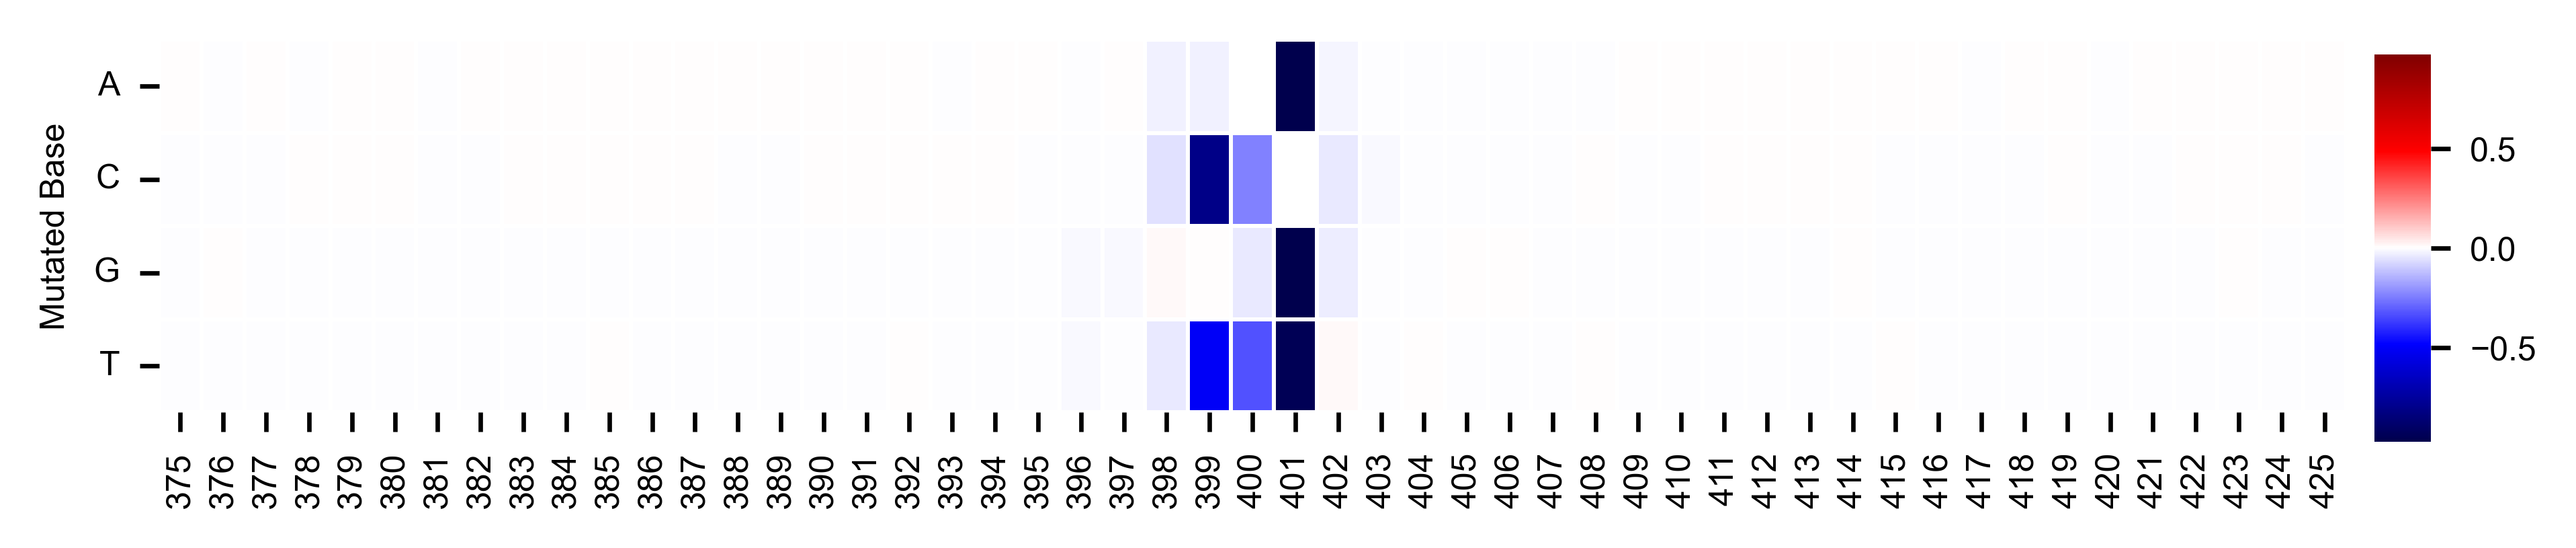

In [23]:
from matplotlib.colors import TwoSlopeNorm

font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 6

# === 筛选固定位置范围 ===
start_pos, end_pos = 375, 425
fixed_range_df = mutation_df[
    (mutation_df['position'] >= start_pos) &
    (mutation_df['position'] <= end_pos)
].copy()

# 生成透视表
pivot_fixed = fixed_range_df.pivot_table(
    values='Delta_pred_prob',
    index='mutated_base',
    columns='position',
    aggfunc='mean'
)

# 全局颜色范围
vmin, vmax = pivot_table.min().min(), pivot_table.max().max()
v_bound = max(abs(vmin), abs(vmax)) if vmin is not None else 1
vmin, vmax = -v_bound, v_bound
norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)

# 图像尺寸设置（宽度固定，高度按突变碱基数量适配）
fig_width = 7
#fig_height = 1.2 + len(pivot_fixed.index) * 0.3
fig_height = 1.2
fig, ax = plt.subplots(figsize=(fig_width, fig_height), dpi=600)

cax = fig.add_axes([0.91, 0.05, 0.02, 0.8])

'''
sns.heatmap(
    pivot_fixed,
    cmap='seismic',
    norm=norm,
    cbar=True,
    ax=ax,
    linewidths=0.5,
    square=True
)
'''
sns.heatmap(
    pivot_fixed,
    #cmap='RdBu_r',
    #cmap='coolwarm',
    cmap='seismic',
    #norm=norm,
    center=0,
    vmin=vmin,  # 统一颜色范围
    vmax=vmax,
    cbar=True,
    cbar_ax=cax,  # ✅ 自定义颜色条轴
    ax=ax,
    linewidths=0.5,
    annot=False,
    #square=True  # 强制格子为正方形
)

# 标签设置
#ax.set_title(f"Mutation Effect Heatmap (Position {start_pos}-{end_pos})", fontsize=7)
#ax.set_xlabel("Position")
ax.set_ylabel("Mutated Base")
ax.set_xlabel('')  # 确保无 X 轴标签
ax.tick_params(axis='x', rotation=90, labelsize=6)
ax.tick_params(axis='y', rotation=0, labelsize=6)

# 保存和展示
os.makedirs("fig", exist_ok=True)
fig.savefig(f"fig/fig4A-1-1.png", bbox_inches='tight', dpi=600)
plt.show()



[新位置 0~800] Label=1 平均 SHAP 值的 Top 10:
位置 401: 绝对平均 SHAP 值 0.1465
位置 400: 绝对平均 SHAP 值 0.0081
位置 399: 绝对平均 SHAP 值 0.0033
位置 389: 绝对平均 SHAP 值 0.0017
位置 398: 绝对平均 SHAP 值 0.0015
位置 153: 绝对平均 SHAP 值 0.0015
位置 428: 绝对平均 SHAP 值 0.0015
位置 20: 绝对平均 SHAP 值 0.0014
位置 114: 绝对平均 SHAP 值 0.0014
位置 391: 绝对平均 SHAP 值 0.0014

[新位置 0~800] Label=1 平均 SHAP 值的 Top 10:
位置 403: 绝对平均 SHAP 值 0.0007
位置 410: 绝对平均 SHAP 值 0.0006
位置 406: 绝对平均 SHAP 值 0.0005
位置 128: 绝对平均 SHAP 值 0.0005
位置 359: 绝对平均 SHAP 值 0.0005
位置 401: 绝对平均 SHAP 值 0.0005
位置 426: 绝对平均 SHAP 值 0.0005
位置 364: 绝对平均 SHAP 值 0.0005
位置 412: 绝对平均 SHAP 值 0.0005
位置 30: 绝对平均 SHAP 值 0.0005


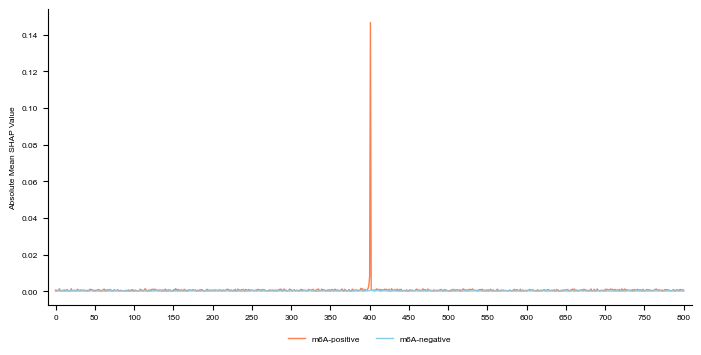

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pickle
import matplotlib.font_manager as fm

font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 6
model_max_length = 803

with open('/work/home/rnasys/lidaoqian/LARMAR/output/test/fig/label1_test_500.pkl', 'rb') as f:
    label1_shap = pickle.load(f)
with open('/work/home/rnasys/lidaoqian/LARMAR/output/test/fig/label0_test_500.pkl', 'rb') as f:
    label0_shap = pickle.load(f)

# 平均 SHAP 值
def compute_mean_shap(shap_values_list, max_length):
    padded_shap_values = []
    for shap_vals in shap_values_list:
        padded = np.zeros(max_length)
        padded[:len(shap_vals)] = shap_vals
        padded_shap_values.append(padded)
    return np.mean(padded_shap_values, axis=0)

mean_shap_label_1 = compute_mean_shap(label1_shap, model_max_length)
mean_shap_label_0 = compute_mean_shap(label0_shap, model_max_length)

shap_label_1_trimmed = mean_shap_label_1[1:-1]
shap_label_0_trimmed = mean_shap_label_0[1:-1]

# Top 10 位置（Label=1）
abs_shap_1_trimmed = np.abs(shap_label_1_trimmed)
top10_indices = np.argsort(abs_shap_1_trimmed)[::-1][:10]
print("\n[新位置 0~800] Label=1 平均 SHAP 值的 Top 10:")
for idx in top10_indices:
    print(f"位置 {idx}: 绝对平均 SHAP 值 {abs_shap_1_trimmed[idx]:.4f}")

abs_shap_0_trimmed = np.abs(shap_label_0_trimmed)
top10_0_indices = np.argsort(abs_shap_0_trimmed)[::-1][:10]
print("\n[新位置 0~800] Label=1 平均 SHAP 值的 Top 10:")
for idx in top10_0_indices:
    print(f"位置 {idx}: 绝对平均 SHAP 值 {abs_shap_0_trimmed[idx]:.4f}")

x = np.arange(801)
plt.figure(figsize=(7, 3.5))

bar_width = 0.4
#plt.bar(x - bar_width/2, np.abs(shap_label_1_trimmed), width=bar_width, color='coral', label='M6A')
#plt.bar(x + bar_width/2, np.abs(shap_label_0_trimmed), width=bar_width, color='skyblue', label='Non-M6A')

plt.plot(x, np.abs(shap_label_1_trimmed), color='coral', label='m6A-positive', linewidth=1)
plt.plot(x, np.abs(shap_label_0_trimmed), color='skyblue', label='m6A-negative', linewidth=1)

#plt.title('Mean Absolute SHAP Values (Position 0–800)', fontweight='bold')
#plt.xlabel('Position in Sequence (0–800)', fontweight='bold')
plt.ylabel('Absolute Mean SHAP Value', fontweight='bold')
plt.xticks(np.arange(0, 801, 50))
plt.yticks()
plt.xlim(-10, 810)

# 设置图例：下方居中，无边框
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('fig/figS4B-1-1.png', dpi=600, bbox_inches='tight')
plt.show()


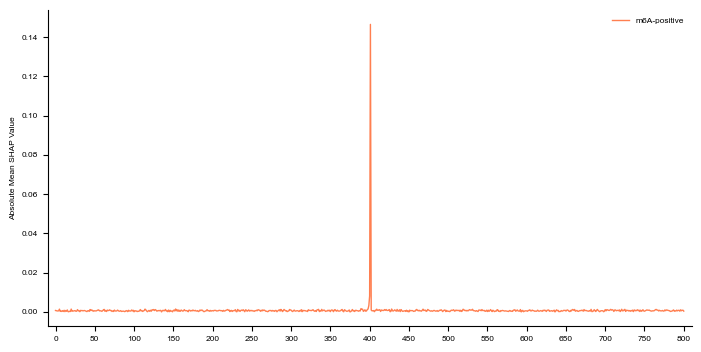

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pickle
import matplotlib.font_manager as fm

font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

with open('/work/home/rnasys/lidaoqian/LARMAR/output/test/fig/label1_test_500.pkl', 'rb') as f:
    label1_shap = pickle.load(f)
with open('/work/home/rnasys/lidaoqian/LARMAR/output/test/fig/label0_test_500.pkl', 'rb') as f:
    label0_shap = pickle.load(f)

# 平均 SHAP 值
def compute_mean_shap(shap_values_list, max_length):
    padded_shap_values = []
    for shap_vals in shap_values_list:
        padded = np.zeros(max_length)
        padded[:len(shap_vals)] = shap_vals
        padded_shap_values.append(padded)
    return np.mean(padded_shap_values, axis=0)

mean_shap_label_1 = compute_mean_shap(label1_shap, model_max_length)
mean_shap_label_0 = compute_mean_shap(label0_shap, model_max_length)

shap_label_1_trimmed = mean_shap_label_1[1:-1]
shap_label_0_trimmed = mean_shap_label_0[1:-1]

x = np.arange(801)
plt.figure(figsize=(14, 3.5))

bar_width = 0.4
#plt.bar(x, np.abs(shap_label_1_trimmed), width=bar_width, color='coral', label='M6A')
plt.plot(x, np.abs(shap_label_1_trimmed), color='coral', label='m6A-positive', linewidth=1)

#plt.title('Mean Absolute SHAP Values (Position 0–800)', fontweight='bold')
#plt.xlabel('Position in Sequence (0–800)', fontweight='bold')
plt.ylabel('Absolute Mean SHAP Value', fontweight='bold')
plt.xticks(np.arange(0, 801, 50))
plt.yticks()
plt.xlim(-10, 810)

# 设置图例：下方居中，无边框
#plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.legend(frameon=False)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('fig/figS4C-1.png', dpi=600, bbox_inches='tight')
plt.show()


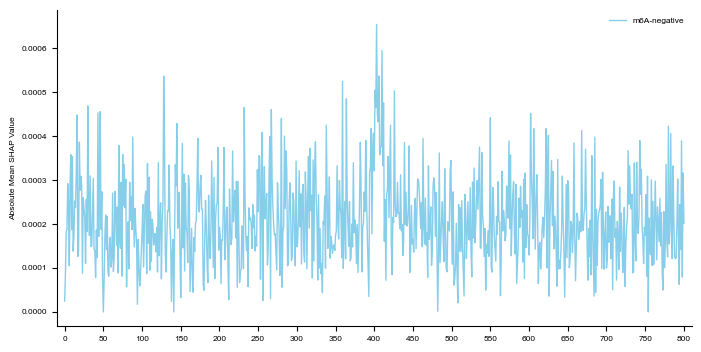

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pickle
import matplotlib.font_manager as fm

font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 6

with open('/work/home/rnasys/lidaoqian/LARMAR/output/test/fig/label1_test_500.pkl', 'rb') as f:
    label1_shap = pickle.load(f)
with open('/work/home/rnasys/lidaoqian/LARMAR/output/test/fig/label0_test_500.pkl', 'rb') as f:
    label0_shap = pickle.load(f)

# 平均 SHAP 值
def compute_mean_shap(shap_values_list, max_length):
    padded_shap_values = []
    for shap_vals in shap_values_list:
        padded = np.zeros(max_length)
        padded[:len(shap_vals)] = shap_vals
        padded_shap_values.append(padded)
    return np.mean(padded_shap_values, axis=0)

mean_shap_label_1 = compute_mean_shap(label1_shap, model_max_length)
mean_shap_label_0 = compute_mean_shap(label0_shap, model_max_length)

shap_label_1_trimmed = mean_shap_label_1[1:-1]
shap_label_0_trimmed = mean_shap_label_0[1:-1]
    
x = np.arange(801)
plt.figure(figsize=(7, 3.5))

bar_width = 0.4
#plt.bar(x, np.abs(shap_label_0_trimmed), width=bar_width, color='skyblue', label='Non-M6A')
plt.plot(x, np.abs(shap_label_0_trimmed), color='skyblue', label='m6A-negative', linewidth=1)

#plt.title('Mean Absolute SHAP Values (Position 0–800)', fontweight='bold')
#plt.xlabel('Position in Sequence (0–800)', fontweight='bold')
plt.ylabel('Absolute Mean SHAP Value', fontweight='bold')
plt.xticks(np.arange(0, 801, 50))
plt.yticks()
plt.xlim(-10, 810)

# 设置图例：下方居中，无边框
plt.legend(frameon=False)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('fig/figS4D-1.png', dpi=600, bbox_inches='tight')
plt.show()


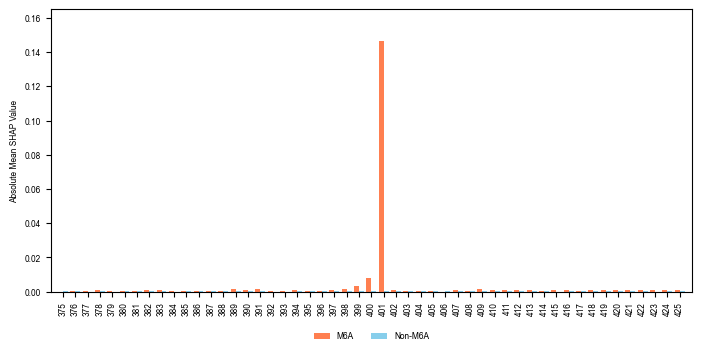

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
import matplotlib.font_manager as fm

font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 6
model_max_length = 803

with open('/work/home/rnasys/lidaoqian/LARMAR/output/test/fig/label1_test_500.pkl', 'rb') as f:
    label1_shap = pickle.load(f)
with open('/work/home/rnasys/lidaoqian/LARMAR/output/test/fig/label0_test_500.pkl', 'rb') as f:
    label0_shap = pickle.load(f)

def compute_mean_shap(shap_values_list, max_length):
    padded_shap_values = []
    for shap_vals in shap_values_list:
        padded = np.zeros(max_length)
        padded[:len(shap_vals)] = shap_vals
        padded_shap_values.append(padded)
    return np.mean(padded_shap_values, axis=0)

mean_shap_label_1 = compute_mean_shap(label1_shap, model_max_length)
mean_shap_label_0 = compute_mean_shap(label0_shap, model_max_length)

shap_label_1_trimmed = mean_shap_label_1[1:-1]  # 长度 801
shap_label_0_trimmed = mean_shap_label_0[1:-1]

# 提取区间 [375, 425]
start, end = 375, 426  # 426 是闭区间右侧+1
x = np.arange(start, end)
y1 = np.abs(shap_label_1_trimmed[start:end])
y0 = np.abs(shap_label_0_trimmed[start:end])
bar_width = 0.4

plt.figure(figsize=(7, 3.5))
plt.bar(x - bar_width/2, y1, width=bar_width, color='coral', label='M6A')
plt.bar(x + bar_width/2, y0, width=bar_width, color='skyblue', label='Non-M6A')

#plt.title('SHAP Values (Position 375–425)', fontsize=6)
#plt.xlabel('Position in Sequence', fontsize=6)
plt.ylabel('Absolute Mean SHAP Value')
plt.xticks(ticks=x, labels=[str(i) for i in x], rotation=90, ha='center')
plt.yticks(np.arange(0, 0.17, 0.02))
plt.xlim(start - 1, end)
plt.ylim(0, 0.165)
# 图例放下方，字体大小6，无边框
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False, fontsize=6)

plt.tight_layout()
plt.savefig('fig/fig4B.png', dpi=600, bbox_inches='tight')
plt.show()


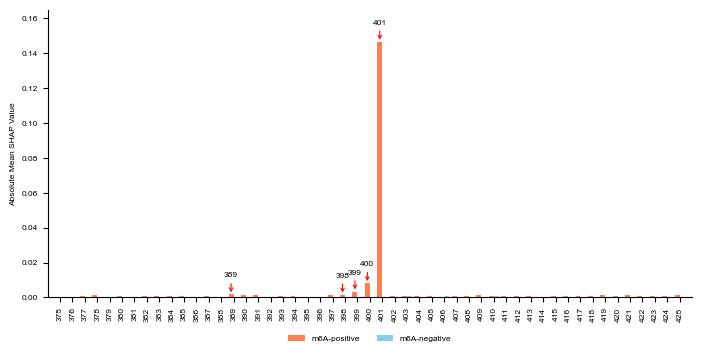

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
import matplotlib.font_manager as fm

font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 6
model_max_length = 803

with open('/work/home/rnasys/lidaoqian/LARMAR/output/test/fig/label1_test_500.pkl', 'rb') as f:
    label1_shap = pickle.load(f)
with open('/work/home/rnasys/lidaoqian/LARMAR/output/test/fig/label0_test_500.pkl', 'rb') as f:
    label0_shap = pickle.load(f)

def compute_mean_shap(shap_values_list, max_length):
    padded_shap_values = []
    for shap_vals in shap_values_list:
        padded = np.zeros(max_length)
        padded[:len(shap_vals)] = shap_vals
        padded_shap_values.append(padded)
    return np.mean(padded_shap_values, axis=0)

mean_shap_label_1 = compute_mean_shap(label1_shap, model_max_length)
mean_shap_label_0 = compute_mean_shap(label0_shap, model_max_length)

shap_label_1_trimmed = mean_shap_label_1[1:-1]  # 长度 801
shap_label_0_trimmed = mean_shap_label_0[1:-1]

# 提取区间 [375, 425]
start, end = 375, 426  # 426 是闭区间右侧+1
x = np.arange(start, end)
y1 = np.abs(shap_label_1_trimmed[start:end])
y0 = np.abs(shap_label_0_trimmed[start:end])
bar_width = 0.4

plt.figure(figsize=(7, 3.5))
plt.bar(x - bar_width/2, y1, width=bar_width, color='coral', label='m6A-positive')
plt.bar(x + bar_width/2, y0, width=bar_width, color='skyblue', label='m6A-negative')

plt.ylabel('Absolute Mean SHAP Value')
plt.xticks(ticks=x, labels=[str(i) for i in x], rotation=90, ha='center')
plt.yticks(np.round(np.arange(0, 0.17, 0.02), 2))
plt.xlim(start - 1, end)
plt.ylim(0, 0.165)

# 找出 Label=1 区间内 Top5 绝对平均 SHAP 位置及对应值
top5_idx_relative = np.argsort(y1)[-5:]  # 取值最大5个的索引（相对区间）
top5_idx_relative = top5_idx_relative[np.argsort(top5_idx_relative)]  # 按顺序排序，便于显示
top5_positions = x[top5_idx_relative]
top5_values = y1[top5_idx_relative]

# 用箭头和文字标注
for pos, val in zip(top5_positions, top5_values):
    plt.annotate(
        f'{pos}', 
        xy=(pos - bar_width/2, val), 
        xytext=(pos - bar_width/2, val + 0.01),
        fontsize=6,
        ha='center',
        arrowprops=dict(arrowstyle='->', color='red', lw=0.8, shrinkA=2, shrinkB=1.5)
    )

plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False, fontsize=6)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('fig/fig4B-1-2.png', dpi=600, bbox_inches='tight')
plt.show()


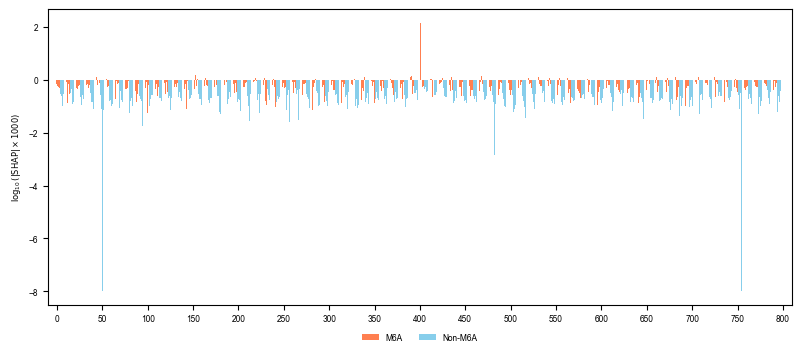

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
import matplotlib.font_manager as fm
font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 6

model_max_length = 803

# 载入 SHAP 值
with open('/work/home/rnasys/lidaoqian/LARMAR/output/test/fig/label1_test_500.pkl', 'rb') as f:
    label1_shap = pickle.load(f)
with open('/work/home/rnasys/lidaoqian/LARMAR/output/test/fig/label0_test_500.pkl', 'rb') as f:
    label0_shap = pickle.load(f)

def compute_mean_shap(shap_values_list, max_length):
    padded_shap_values = []
    for shap_vals in shap_values_list:
        padded = np.zeros(max_length)
        padded[:len(shap_vals)] = shap_vals
        padded_shap_values.append(padded)
    return np.mean(padded_shap_values, axis=0)

# 计算均值并去除 CLS 和 SEP
mean_shap_label_1 = compute_mean_shap(label1_shap, model_max_length)[1:-1]  # shape: (801,)
mean_shap_label_0 = compute_mean_shap(label0_shap, model_max_length)[1:-1]

# 转换：abs × 1000 → log10
epsilon = 1e-8  # 防止 log(0) 出现 nan
log_shap_label_1 = np.log10(np.abs(mean_shap_label_1 * 1000) + epsilon)
log_shap_label_0 = np.log10(np.abs(mean_shap_label_0 * 1000) + epsilon)

# 可视化
x = np.arange(801)
bar_width = 0.4

plt.figure(figsize=(8, 3.5))
plt.bar(x - bar_width/2, log_shap_label_1, width=bar_width, color='coral', label='M6A')
plt.bar(x + bar_width/2, log_shap_label_0, width=bar_width, color='skyblue', label='Non-M6A')

#plt.title(r'$\log_{10}(|\mathrm{SHAP}| \times 1000)$ (Position 0–800)', fontsize=14, fontweight='bold')
#plt.xlabel('Position in Sequence (0–800)', fontweight='bold')
plt.ylabel(r'$\log_{10}(|\mathrm{SHAP}| \times 1000)$', fontweight='bold')
plt.xticks(np.arange(0, 801, 50))
plt.yticks()
plt.xlim(-10, 810)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.tight_layout()
plt.savefig('fig/fig4_test_log.png', dpi=300)
plt.show()


## Fig4-ppt

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.font_manager as fm
import os

# === 字体设置（Arial，适配期刊） ===
font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

# === 输入文件路径 ===
csv_file = "/work/home/rnasys/lidaoqian/LARMAR/output/test/mutation/cell5_mutated_sequences_801_label1_100_predict_linear.csv"
df = pd.read_csv(csv_file)

# === 检查必要列 ===
required_columns = ['seq', 'predict_probs', 'is_original', 'original_seq', 'position', 'mutated_base']
if not all(col in df.columns for col in required_columns):
    raise ValueError(f"CSV 文件必须包含以下列：{', '.join(required_columns)}")

# === 提取原始序列 ===
original_df = df[df['is_original'] == 1].copy()
if original_df.empty:
    raise ValueError("未找到原始序列（is_original == 1）")

print(f"共分析 {len(original_df)} 条原始序列")

# === 计算 Delta_pred_prob ===
original_probs = dict(zip(original_df['original_seq'], original_df['predict_probs']))
def calculate_delta_prob(row):
    if row['is_original'] == 1:
        return 0
    return row['predict_probs'] - original_probs.get(row['original_seq'], 0)
df['Delta_pred_prob'] = df.apply(calculate_delta_prob, axis=1)

# === 提取突变数据并整理 ===
mutation_df = df[(df['is_original'] == 0) & (df['Delta_pred_prob'].notnull())].copy()
mutation_df['position'] = mutation_df['position'].astype(int) - 1  # 0-based

# === 以 position=400 作为中心点，生成相对坐标 ===
center = 400
mutation_df['rel_position'] = mutation_df['position'] - center

# === 聚合数据 ===
pivot_table = mutation_df.pivot_table(
    values='Delta_pred_prob',
    index='mutated_base',
    columns='rel_position',   # 用相对位置
    aggfunc='mean'
)

# === 分段参数 ===
segment_size = 91
positions = pivot_table.columns
segments = [positions[i:i + segment_size] for i in range(0, len(positions), segment_size)]
n_segments = len(segments)

# === 全局颜色范围 ===
vmin, vmax = pivot_table.min().min(), pivot_table.max().max()
v_bound = max(abs(vmin), abs(vmax)) if vmin is not None else 1
vmin, vmax = -v_bound, v_bound

# === 图像参数 ===
fixed_width = 14         # 总宽度（英寸）
segment_height = 1    # 每段热图高度
gap_height = 0.8        # 每段之间间隙
dpi = 600
fig_height = n_segments * (segment_height + gap_height) + 0.5

# === 创建图像 ===
fig = plt.figure(figsize=(fixed_width, fig_height), dpi=dpi)

for i, segment in enumerate(segments):
    sub_pivot = pivot_table[segment]

    # 位置换算：从上往下排布
    total_height = fig_height
    h = segment_height / total_height
    g = gap_height / total_height
    bottom = 1.0 - (i + 1) * h - i * g

    # 创建主热图轴
    ax = fig.add_axes([0.05, bottom, 0.8, h])

    # 仅最后一段添加颜色条
    if i == n_segments - 1:
        cbar_bottom = bottom
        cbar_height = h
        cbar_left = 0.87
        cbar_width = 0.02
        cax = fig.add_axes([cbar_left, cbar_bottom, cbar_width, cbar_height])
    else:
        cax = None

    sns.heatmap(
        sub_pivot,
        cmap='seismic',
        center=0,
        vmin=vmin,
        vmax=vmax,
        cbar_ax=cax if cax else None,
        cbar=i == n_segments - 1,
        ax=ax,
        linewidths=0.5,
        annot=False,
    )

    # === 设置轴标签 ===
    ax.set_ylabel('Mutated Base')
    ax.tick_params(axis='y', rotation=0, labelleft=True)

    # 设置 x 轴 tick 对应到 sub_pivot 的列（相对位置）
    ax.set_xticks(np.arange(len(sub_pivot.columns)) + 0.5)  # 热图格子居中

    # 去掉 frame 和 xlabel
    ax.set_xlabel('')
    ax.set_frame_on(False)

# === 保存图像和数据 ===
os.makedirs("fig-1", exist_ok=True)
fig.savefig("fig-1/fig4SA-1-2.png", dpi=dpi, bbox_inches='tight')
# pivot_table.to_csv("fig/cell5_100_mutation_effect.csv", index=True, float_format="%.6f")

plt.show()


共分析 100 条原始序列


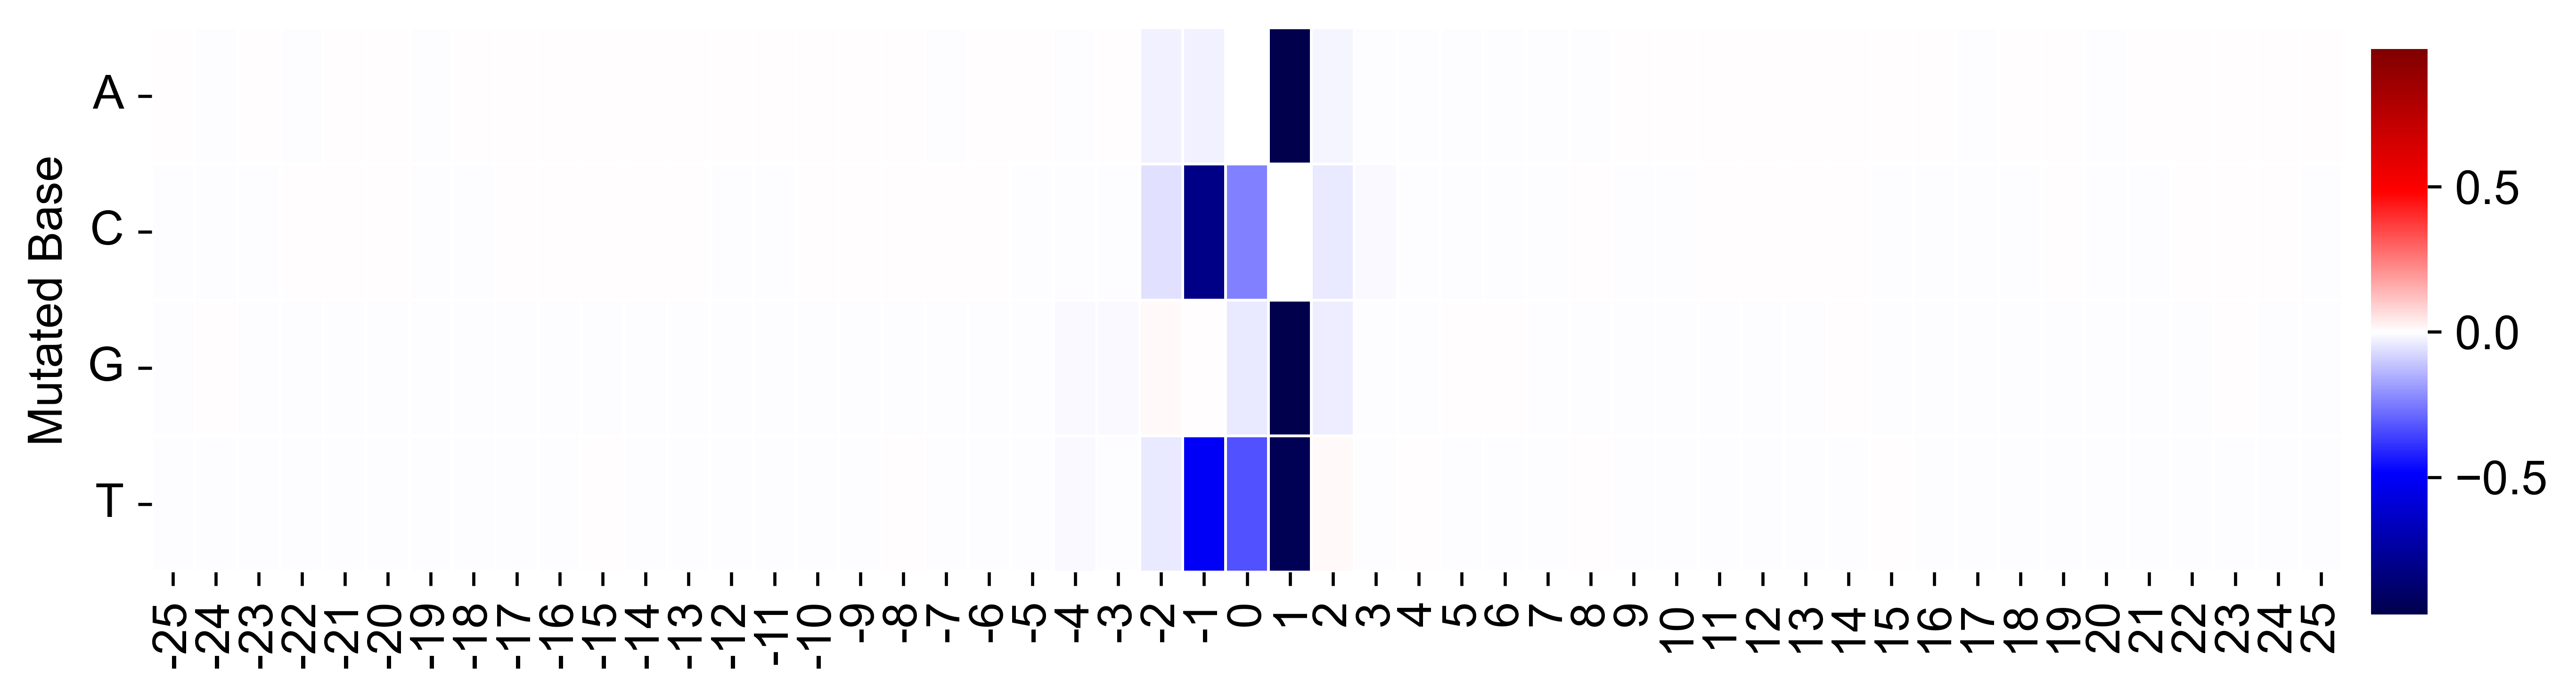

In [53]:
from matplotlib.colors import TwoSlopeNorm
import os
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# === 字体设置（Arial，适配期刊） ===
font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

# === 筛选固定位置范围 ===
start_pos, end_pos = 375, 425
fixed_range_df = mutation_df[
    (mutation_df['position'] >= start_pos) &
    (mutation_df['position'] <= end_pos)
].copy()

# === 以 400 为中心点，生成相对坐标 ===
center = 400
fixed_range_df['rel_position'] = fixed_range_df['position'] - center

# === 生成透视表（用相对位置作为列） ===
pivot_fixed = fixed_range_df.pivot_table(
    values='Delta_pred_prob',
    index='mutated_base',
    columns='rel_position',
    aggfunc='mean'
)

# === 全局颜色范围（和大图保持一致） ===
vmin, vmax = pivot_table.min().min(), pivot_table.max().max()
v_bound = max(abs(vmin), abs(vmax)) if vmin is not None else 1
vmin, vmax = -v_bound, v_bound
norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)

# === 图像尺寸设置 ===
fig_width = 10
fig_height = 2.5
fig, ax = plt.subplots(figsize=(fig_width, fig_height), dpi=600)

cax = fig.add_axes([0.91, 0.05, 0.02, 0.8])

# === 绘制热图 ===
sns.heatmap(
    pivot_fixed,
    cmap='seismic',
    center=0,
    vmin=vmin,
    vmax=vmax,
    cbar=True,
    cbar_ax=cax,   # 自定义颜色条轴
    ax=ax,
    linewidths=0.5,
    annot=False,
)

# === 标签设置 ===
ax.set_ylabel("Mutated Base")
ax.set_xlabel("")  
ax.tick_params(axis='x', rotation=90, labelsize=12)
ax.tick_params(axis='y', rotation=0, labelsize=12)

# 设置 x 轴刻度为相对位置
ax.set_xticks(np.arange(len(pivot_fixed.columns)) + 0.5)
ax.set_xticklabels(pivot_fixed.columns, rotation=90)

# === 保存和展示 ===
os.makedirs("fig-1", exist_ok=True)
fig.savefig("fig-1/fig4A-1-2.png", bbox_inches='tight', dpi=600)
plt.show()


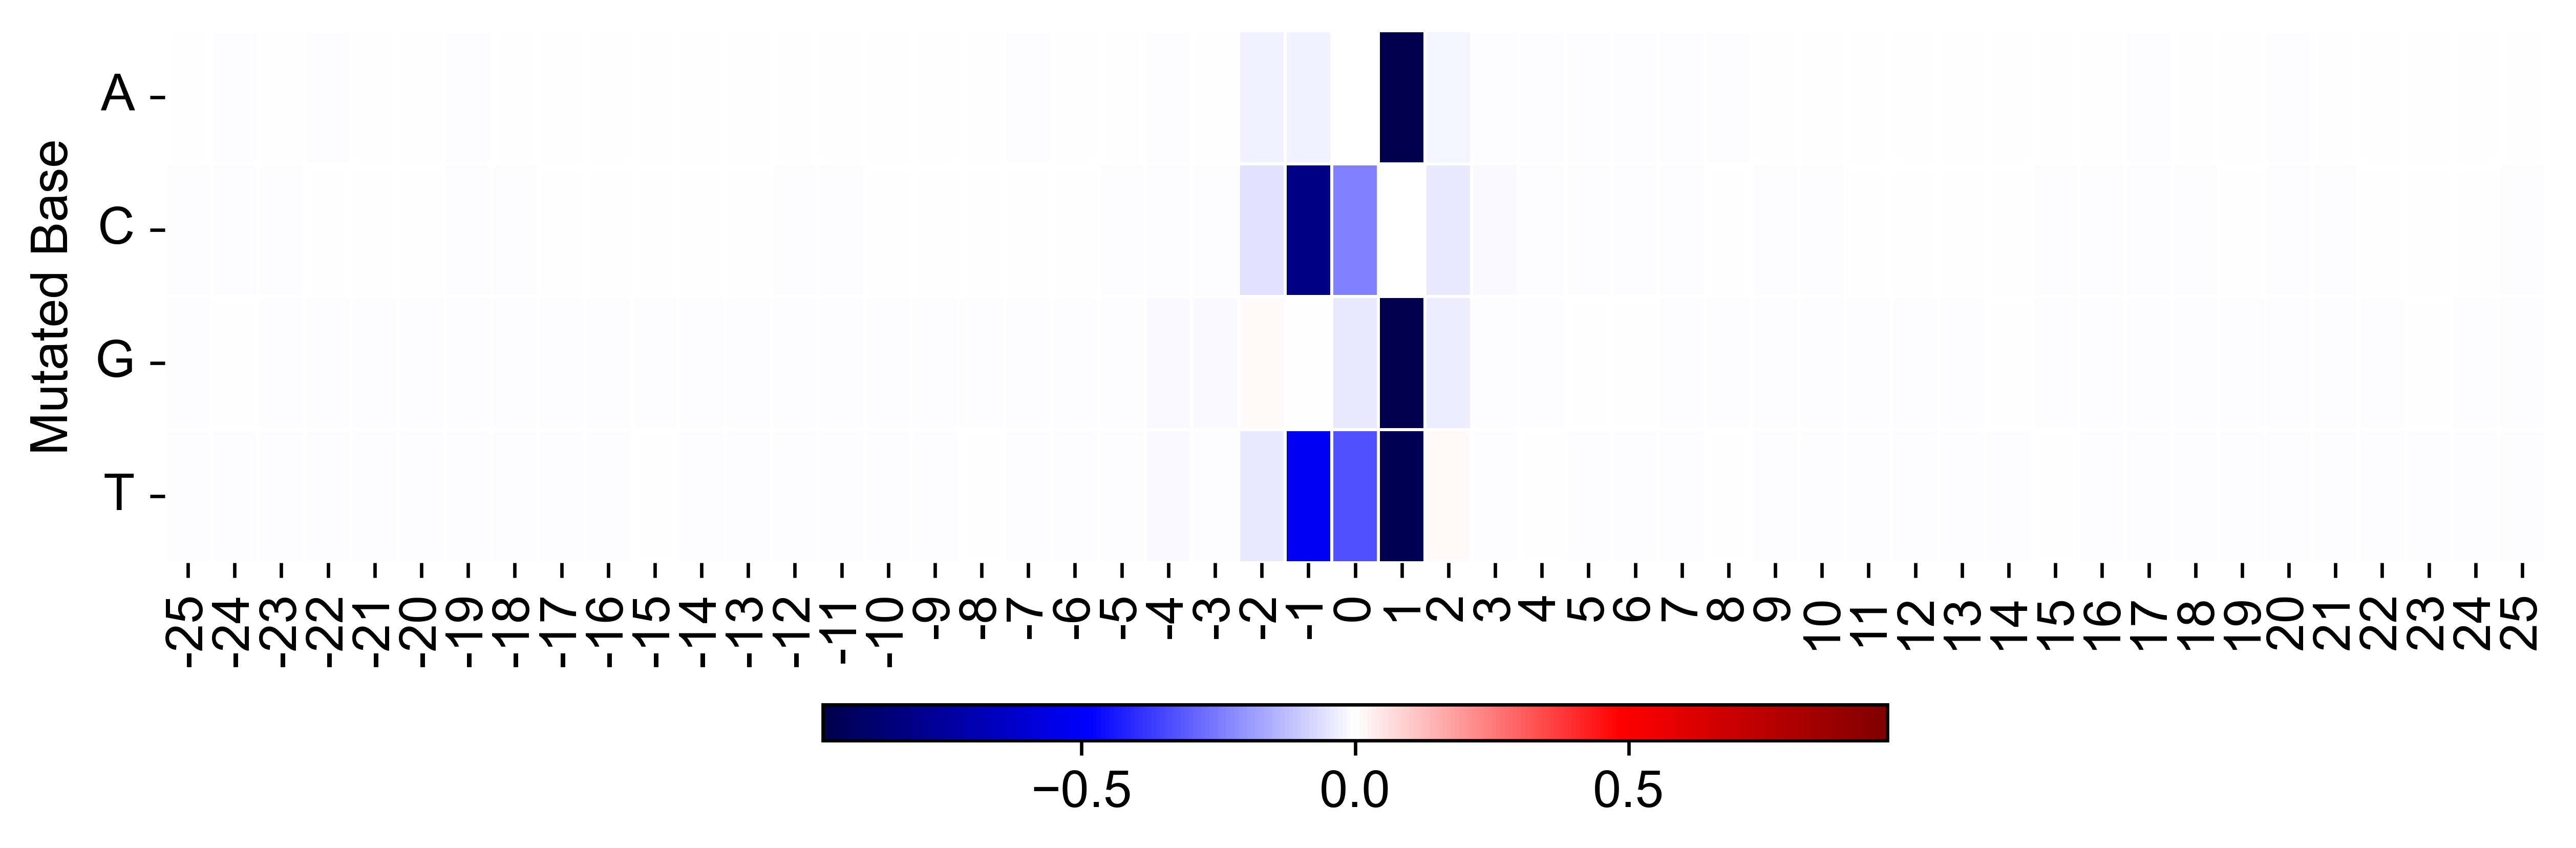

In [30]:
from matplotlib.colors import TwoSlopeNorm
import os
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# === 字体设置（Arial，适配期刊） ===
font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

# === 筛选固定位置范围 ===
start_pos, end_pos = 375, 425
fixed_range_df = mutation_df[
    (mutation_df['position'] >= start_pos) &
    (mutation_df['position'] <= end_pos)
].copy()

# === 以 400 为中心点，生成相对坐标 ===
center = 400
fixed_range_df['rel_position'] = fixed_range_df['position'] - center

# === 生成透视表 ===
pivot_fixed = fixed_range_df.pivot_table(
    values='Delta_pred_prob',
    index='mutated_base',
    columns='rel_position',
    aggfunc='mean'
)

# === 全局颜色范围（和大图保持一致） ===
vmin, vmax = pivot_table.min().min(), pivot_table.max().max()
v_bound = max(abs(vmin), abs(vmax)) if vmin is not None else 1
vmin, vmax = -v_bound, v_bound
norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)

# === 图像尺寸设置 ===
fig_width = 10
fig_height = 3
fig, ax = plt.subplots(figsize=(fig_width, fig_height), dpi=600)

# === 绘制热图（不直接加 cbar_ax） ===
im = sns.heatmap(
    pivot_fixed,
    cmap='seismic',
    center=0,
    vmin=vmin,
    vmax=vmax,
    cbar=False,     # 先不画colorbar
    ax=ax,
    linewidths=0.5,
    annot=False,
)

# === 自定义颜色条：放在底部居中 ===
cbar = fig.colorbar(im.collections[0],
                    ax=ax,
                    orientation='horizontal',
                    fraction=0.05,   # 控制长度
                    pad=0.2,        # 控制与图的距离
                    aspect=30)
#cbar.set_label('Δ Predicted Probability', fontsize=12)
cbar.ax.tick_params(labelsize=12)

# === 坐标轴美化 ===
ax.set_ylabel("Mutated Base")
ax.set_xlabel("")  
ax.tick_params(axis='x', rotation=90, labelsize=12)
ax.tick_params(axis='y', rotation=0, labelsize=12)
ax.set_xticks(np.arange(len(pivot_fixed.columns)) + 0.5)
ax.set_xticklabels(pivot_fixed.columns, rotation=90)

# === 去掉上右边框 ===
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# === 保存 ===
os.makedirs("fig-1", exist_ok=True)
fig.savefig("fig-1/fig4A-1-2.png", bbox_inches='tight', dpi=600)
plt.show()


提取到 100 条序列片段用于绘制 logo


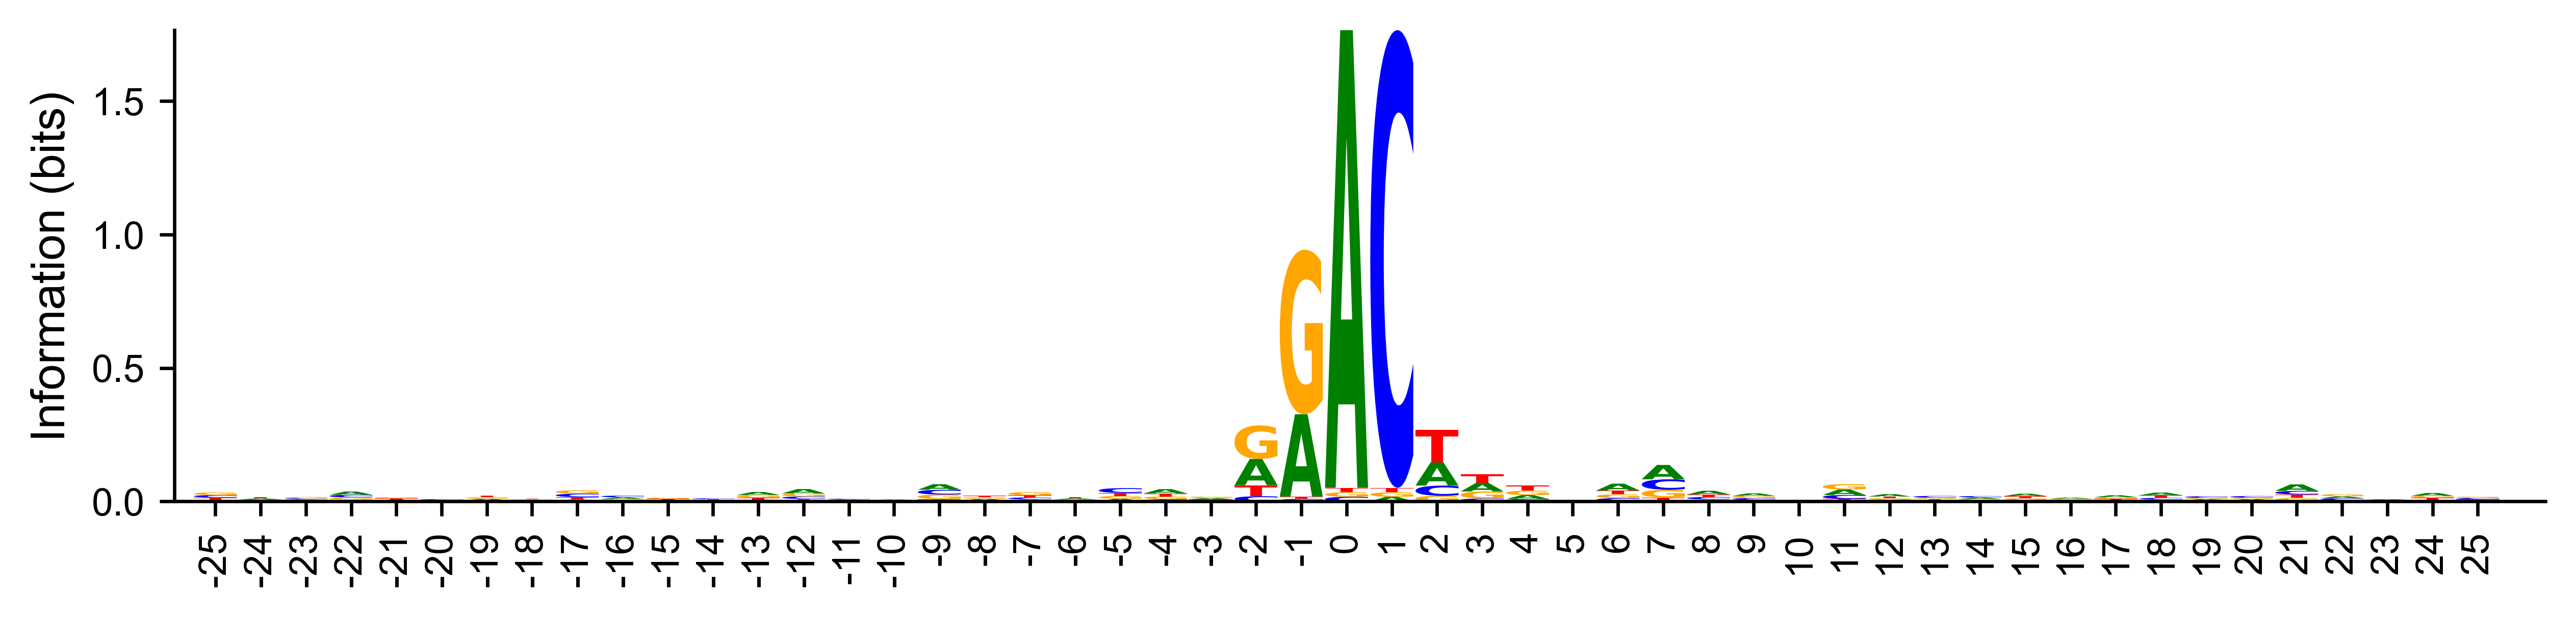

In [31]:
import pandas as pd
import logomaker
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import numpy as np
import os

# ===============================
# 字体设置（期刊用 Arial）
# ===============================
font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

# ===============================
# 参数设置
# ===============================
start_pos = 375   # 序列起始位置
end_pos = 426     # 序列结束位置（含）
center = 401      # 中心位置

# ===============================
# 提取序列片段
# ===============================
subseqs = []
for seq in original_df['seq']:
    if len(seq) >= end_pos:
        subseqs.append(seq[start_pos-1:end_pos])  # Python 0-based indexing
sub_df = pd.DataFrame({'subseq': subseqs})
print(f"提取到 {len(sub_df)} 条序列片段用于绘制 logo")

# ===============================
# 生成信息量矩阵
# ===============================
counts_mat = logomaker.alignment_to_matrix(
    sequences=sub_df['subseq'],
    to_type='information'  # 可改 'probability' 显示频率
)

# ===============================
# 绘制 Logo
# ===============================
fig, ax = plt.subplots(figsize=(10, 2), dpi=600)
logo = logomaker.Logo(
    counts_mat,
    ax=ax,
    color_scheme='classic'
)

# ===============================
# 生成相对位置（相对于 center）
# ===============================
rel_positions = np.arange(start_pos, end_pos + 1) - center  # e.g., -25 ~ 0 ~ +25

# 设置 X 轴刻度和范围，使每个碱基柱与标签对齐
n = counts_mat.shape[0]
ax.set_xticks(np.arange(n))          # 每个柱体一个刻度
ax.set_xticklabels(rel_positions)    # 对应相对坐标
ax.set_xlim(0.1, n +0.5)          # 左右半格对齐柱体

# ===============================
# 标签美化
# ===============================
#ax.set_xlabel(f"Position relative to {center}", fontsize=11)
ax.set_ylabel("Information (bits)", fontsize=11)
ax.tick_params(axis='x', rotation=90, labelsize=9)
ax.tick_params(axis='y', labelsize=9)
sns.despine(ax=ax, top=True, right=True)

# ===============================
# 保存图像
# ===============================
os.makedirs("fig-1", exist_ok=True)
fig.savefig("fig-1/fig4A-origin-logo-centered.png", bbox_inches='tight', dpi=600)
plt.show()


In [ ]:
import pandas as pd
import logomaker
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import numpy as np
import os

# ===============================
# 字体设置（期刊用 Arial）
# ===============================
font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

# === 输入文件路径 ===
csv_file = "/work/home/rnasys/lidaoqian/LARMAR/output/test/mutation/cell5_mutated_sequences_801_label1_100_predict_linear.csv"
df = pd.read_csv(csv_file)

# === 检查必要列 ===
required_columns = ['seq', 'predict_probs', 'is_original', 'original_seq', 'position', 'mutated_base']
if not all(col in df.columns for col in required_columns):
    raise ValueError(f"CSV 文件必须包含以下列：{', '.join(required_columns)}")

# === 提取原始序列 ===
original_df = df[df['is_original'] == 1].copy()
if original_df.empty:
    raise ValueError("未找到原始序列（is_original == 1）")

print(f"共分析 {len(original_df)} 条原始序列")

# === 计算 Delta_pred_prob ===
original_probs = dict(zip(original_df['original_seq'], original_df['predict_probs']))
def calculate_delta_prob(row):
    if row['is_original'] == 1:
        return 0
    return row['predict_probs'] - original_probs.get(row['original_seq'], 0)
df['Delta_pred_prob'] = df.apply(calculate_delta_prob, axis=1)

# === 提取突变数据并整理 ===
mutation_df = df[(df['is_original'] == 0) & (df['Delta_pred_prob'].notnull())].copy()
mutation_df['position'] = mutation_df['position'].astype(int) - 1  # 0-based

# ===============================
# 参数设置
# ===============================
start_pos = 375   # 序列起始位置
end_pos = 426     # 序列结束位置（含）
center = 401      # 中心位置

# ===============================
# 提取序列片段
# ===============================
mut_df = df[df['is_original'] == 0].copy()  # 筛选突变序列
subseqs = []
for seq in mut_df['seq']:
    if len(seq) >= end_pos:
        subseqs.append(seq[start_pos-1:end_pos])  # Python 0-based indexing
sub_df = pd.DataFrame({'subseq': subseqs})
print(f"提取到 {len(sub_df)} 条序列片段用于绘制 logo")

# ===============================
# 生成信息量矩阵
# ===============================
counts_mat = logomaker.alignment_to_matrix(
    sequences=sub_df['subseq'],
    to_type='information'  # 可改 'probability' 显示频率
)

# ===============================
# 绘制 Logo
# ===============================
fig, ax = plt.subplots(figsize=(10, 2), dpi=600)
logo = logomaker.Logo(
    counts_mat,
    ax=ax,
    color_scheme='classic'
)

# ===============================
# 生成相对位置（相对于 center）
# ===============================
rel_positions = np.arange(start_pos, end_pos + 1) - center  # e.g., -25 ~ 0 ~ +25

# 设置 X 轴刻度和范围，使每个碱基柱与标签对齐
n = counts_mat.shape[0]
ax.set_xticks(np.arange(n))          # 每个柱体一个刻度
ax.set_xticklabels(rel_positions)    # 对应相对坐标
ax.set_xlim(0.1, n +0.5)          # 左右半格对齐柱体

# ===============================
# 标签美化
# ===============================
#ax.set_xlabel(f"Position relative to {center}", fontsize=11)
ax.set_ylabel("Information (bits)", fontsize=11)
ax.tick_params(axis='x', rotation=90, labelsize=9)
ax.tick_params(axis='y', labelsize=9)
sns.despine(ax=ax, top=True, right=True)

# ===============================
# 保存图像
# ===============================
os.makedirs("fig-1", exist_ok=True)
fig.savefig("fig-1/fig4A-mutation-logo-centered.png", bbox_inches='tight', dpi=600)
plt.show()


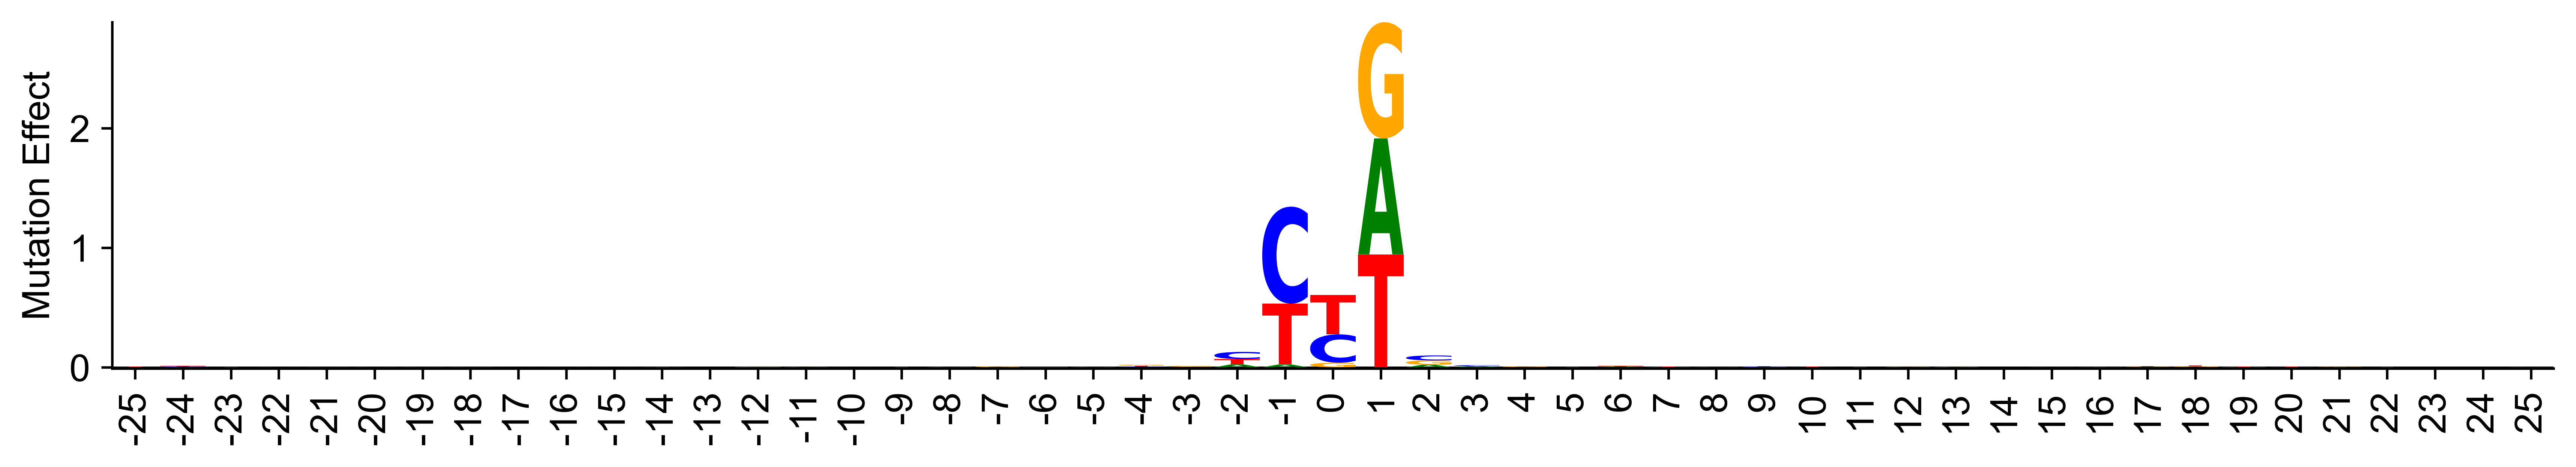

In [32]:
import logomaker
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
import os

# === 字体设置 ===
font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

# === 筛选区间 ===
start_pos, end_pos = 375, 425
df = mutation_df[
    (mutation_df['position'] >= start_pos) &
    (mutation_df['position'] <= end_pos)
].copy()

# === 以 400 为中心生成相对坐标 ===
center = 400
df['rel_position'] = df['position'] - center

# === 构建 pivot 表（每个位置的每个碱基平均效应） ===
pivot_logo = df.pivot_table(
    values='Delta_pred_prob',
    index='mutated_base',
    columns='rel_position',
    aggfunc='mean'
).reindex(index=['A', 'C', 'G', 'T']).fillna(0)

# === 转置，logomaker 需要行=位置，列=碱基 ===
pivot_logo = pivot_logo.T
pivot_logo = -pivot_logo  # 反转符号，让向上表示模型讨厌

# === 获取统一范围（和热图一致） ===
vmin, vmax = pivot_logo.min().min(), pivot_logo.max().max()
v_bound = max(abs(vmin), abs(vmax))

# === 绘制 Logo 图 ===
fig, ax = plt.subplots(figsize=(14, 2), dpi=600)

logomaker.Logo(
    pivot_logo,
    ax=ax,
    color_scheme='classic',  # 可选: 'chemistry', 'dnaview'
    shade_below=0,
    fade_below=0.5
)

# --- 设置 Y 轴标签 ---
ax.set_ylabel("Mutation Effect")

# --- 去掉上、右边框 ---
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# --- 设置 X 轴刻度 ---
ax.set_xticks(np.arange(-25, 26, 1))
ax.set_xticklabels(np.arange(-25, 26, 1), rotation=90)



os.makedirs("fig-1", exist_ok=True)
fig.savefig("fig-1/fig4A-logo-effect.png", bbox_inches='tight', dpi=600)
plt.show()


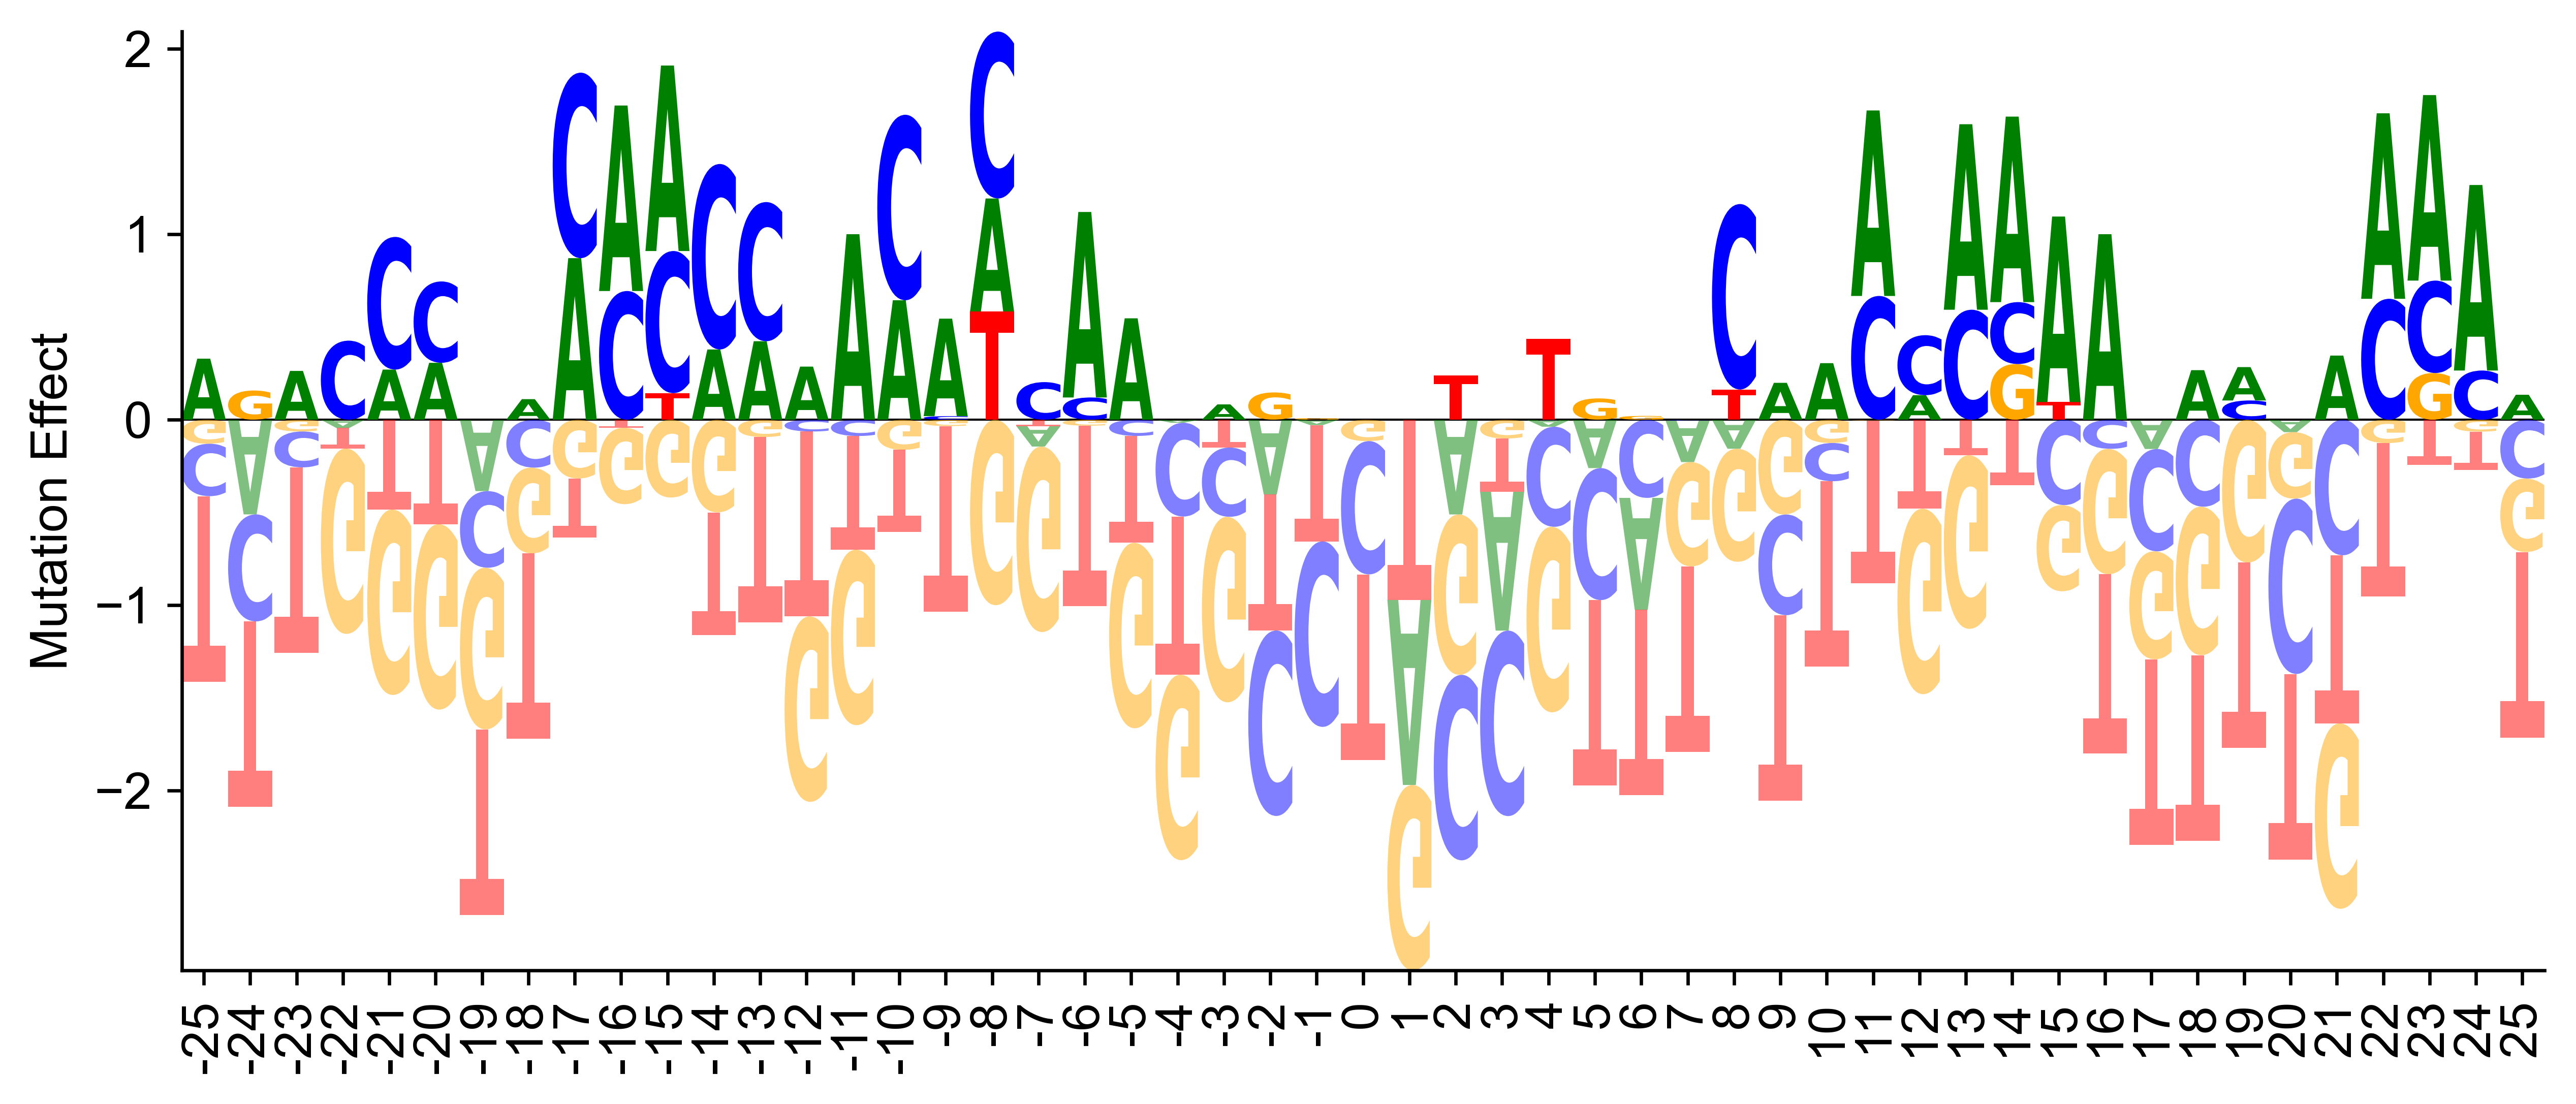

In [56]:
import logomaker
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
import os

# === 字体设置 ===
font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

# === 筛选区间 ===
start_pos, end_pos = 375, 425
df = mutation_df[
    (mutation_df['position'] >= start_pos) &
    (mutation_df['position'] <= end_pos)
].copy()

# === 以 400 为中心生成相对坐标 ===
center = 400
df['rel_position'] = df['position'] - center

# === 构建 pivot 表（每个位置的每个碱基平均效应） ===
pivot_logo = df.pivot_table(
    values='Delta_pred_prob',
    index='mutated_base',
    columns='rel_position',
    aggfunc='mean'
).reindex(index=['A', 'C', 'G', 'T']).fillna(0)

# === 转置，logomaker 需要行=位置，列=碱基 ===
pivot_logo = pivot_logo.T

# === 反转符号（让向上表示模型讨厌） ===
#pivot_logo = -pivot_logo

# === 按行归一化到 [-1, 1] ===
pivot_logo_norm = pivot_logo.copy()
for pos in pivot_logo_norm.index:
    max_abs = pivot_logo_norm.loc[pos].abs().max()
    if max_abs != 0:
        pivot_logo_norm.loc[pos] = pivot_logo_norm.loc[pos] / max_abs

# === 绘制 Logo 图 ===
fig, ax = plt.subplots(figsize=(10, 4), dpi=600)

logomaker.Logo(
    pivot_logo_norm,
    ax=ax,
    color_scheme='classic',  # 可选: 'chemistry', 'dnaview'
    shade_below=0,
    fade_below=0.5
)

# --- 设置 Y 轴标签 ---
ax.set_ylabel("Mutation Effect")

# --- 去掉上、右边框 ---
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# --- 设置 X 轴刻度 ---
ax.set_xticks(np.arange(-25, 26, 1))
ax.set_xticklabels(np.arange(-25, 26, 1), rotation=90)

# === 保存图像 ===
os.makedirs("fig-1", exist_ok=True)
fig.savefig("fig-1/fig4A-logo-effect-normalized.png", bbox_inches='tight', dpi=600)
plt.show()


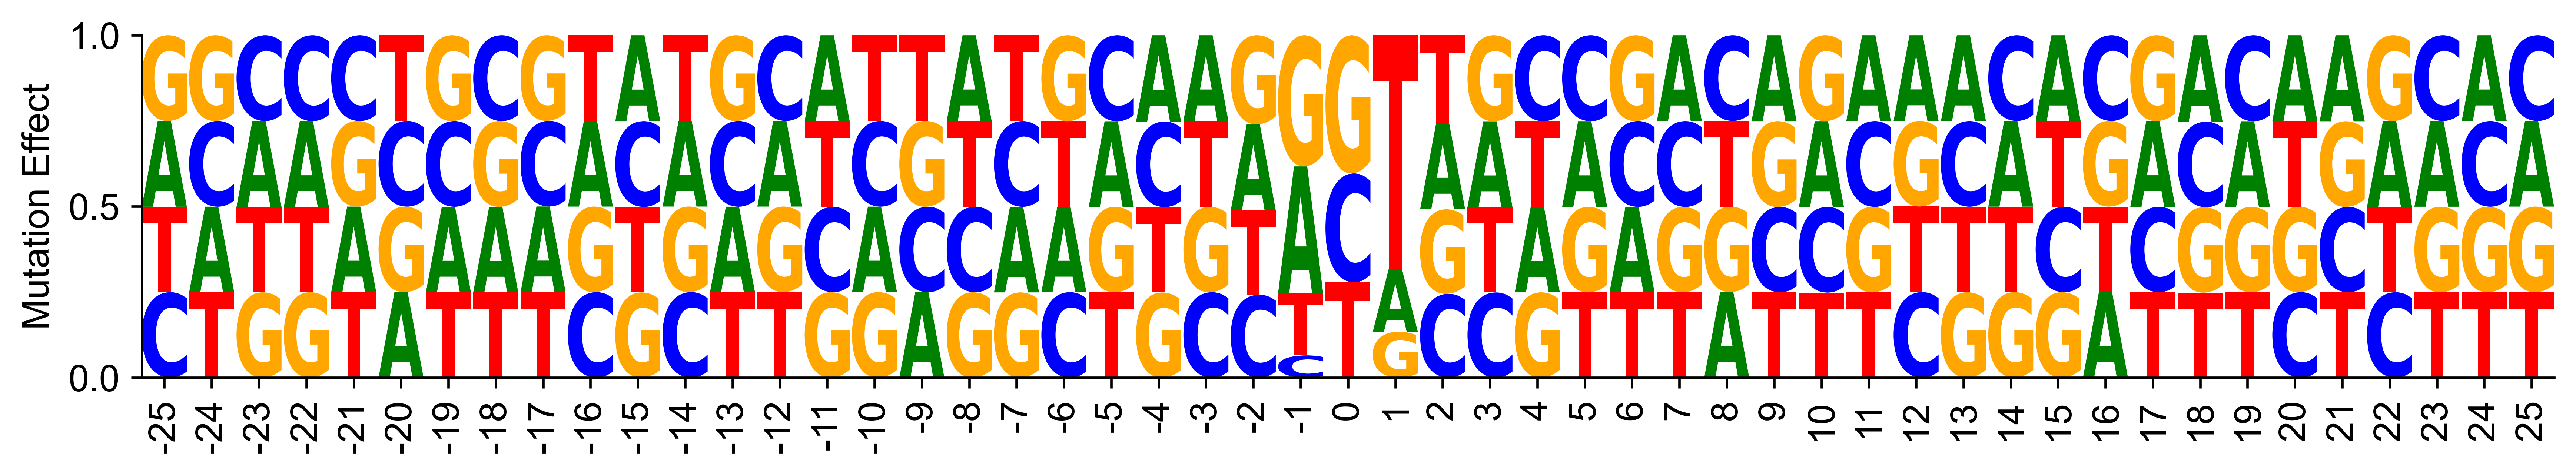

In [36]:
import pandas as pd
import numpy as np
import logomaker
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import os

# === 字体设置 ===
font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

# === 参数 ===
start_pos, end_pos = 375, 425
center = 400

# === 读取数据 ===
# mutation_df = pd.read_csv("your_file.csv")
df = mutation_df.copy()

# === 提取目标区间 ===
df = df[(df['position'] >= start_pos) & (df['position'] <= end_pos)].copy()
df['rel_position'] = df['position'] - center

# === Step 1: 获取原始序列的预测值（作为参考） ===
orig_df = df[df['is_original'] == True][['original_seq', 'predict_probs']].drop_duplicates()
orig_dict = dict(zip(orig_df['original_seq'], orig_df['predict_probs']))

# === Step 2: 计算每个突变的 Δpred_prob ===
# Δ = 突变后预测值 - 原始序列预测值
df['original_predict'] = df['original_seq'].map(orig_dict)
df['Delta_pred_prob'] = df['predict_probs'] - df['original_predict']

# === Step 3: 按位置 + 碱基取平均预测值 ===
base_pref = (
    df.groupby(['rel_position', 'mutated_base'])['predict_probs']
    .mean()
    .reset_index()
)

# === Step 4: pivot 成矩阵 ===
pivot_pref = base_pref.pivot(index='rel_position', columns='mutated_base', values='predict_probs')
pivot_pref = pivot_pref.reindex(columns=['A', 'C', 'G', 'T']).fillna(0)

# === Step 5: 归一化 (optional, 保证 logo 高度可比) ===
pivot_pref = pivot_pref.div(pivot_pref.sum(axis=1), axis=0)

# === Step 6: 绘制 Logo ===
fig, ax = plt.subplots(figsize=(14, 2), dpi=600)

logomaker.Logo(
    pivot_pref,
    ax=ax,
    color_scheme='classic',
    shade_below=0,
    fade_below=0.5
)

# --- 设置 Y 轴标签 ---
ax.set_ylabel("Mutation Effect")

# --- 去掉上、右边框 ---
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# --- 设置 X 轴刻度 ---
ax.set_xticks(np.arange(-25, 26, 1))
ax.set_xticklabels(np.arange(-25, 26, 1), rotation=90)

os.makedirs("fig-1", exist_ok=True)
fig.savefig("fig-1/fig4A-logo-norm-preference-from-mutations.png", bbox_inches='tight', dpi=600)
plt.show()



[相对位置 -400~+400] Label=1 平均 SHAP 值的 Top 10:
位置 1: 绝对平均 SHAP 值 0.1465
位置 0: 绝对平均 SHAP 值 0.0081
位置 -1: 绝对平均 SHAP 值 0.0033
位置 -11: 绝对平均 SHAP 值 0.0017
位置 -2: 绝对平均 SHAP 值 0.0015
位置 -247: 绝对平均 SHAP 值 0.0015
位置 28: 绝对平均 SHAP 值 0.0015
位置 -380: 绝对平均 SHAP 值 0.0014
位置 -286: 绝对平均 SHAP 值 0.0014
位置 -9: 绝对平均 SHAP 值 0.0014

[相对位置 -400~+400] Label=0 平均 SHAP 值的 Top 10:
位置 3: 绝对平均 SHAP 值 0.0007
位置 10: 绝对平均 SHAP 值 0.0006
位置 6: 绝对平均 SHAP 值 0.0005
位置 -272: 绝对平均 SHAP 值 0.0005
位置 -41: 绝对平均 SHAP 值 0.0005
位置 1: 绝对平均 SHAP 值 0.0005
位置 26: 绝对平均 SHAP 值 0.0005
位置 -36: 绝对平均 SHAP 值 0.0005
位置 12: 绝对平均 SHAP 值 0.0005
位置 -370: 绝对平均 SHAP 值 0.0005


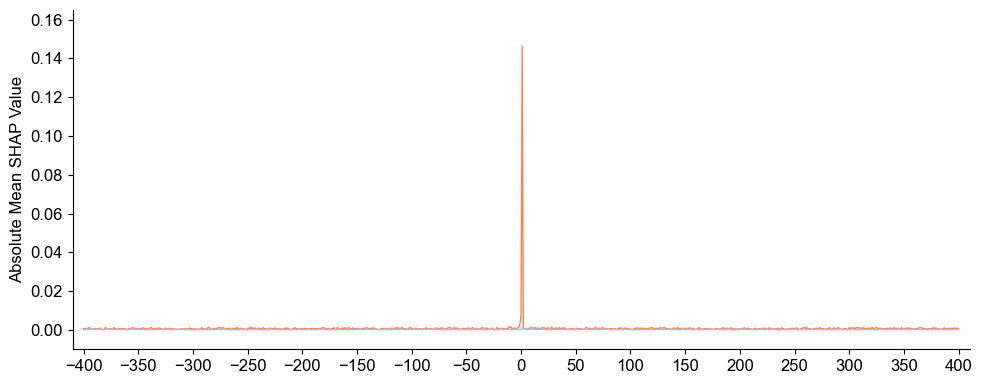

In [57]:
import matplotlib.pyplot as plt
import numpy as np
import pickle
import matplotlib.font_manager as fm
import os

# === 字体设置（Arial，适配期刊） ===
font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12
model_max_length = 803

# === 读取 SHAP 值 ===
with open('/work/home/rnasys/lidaoqian/LARMAR/output/test/fig/label1_test_500.pkl', 'rb') as f:
    label1_shap = pickle.load(f)
with open('/work/home/rnasys/lidaoqian/LARMAR/output/test/fig/label0_test_500.pkl', 'rb') as f:
    label0_shap = pickle.load(f)

# === 平均 SHAP 值 ===
def compute_mean_shap(shap_values_list, max_length):
    padded_shap_values = []
    for shap_vals in shap_values_list:
        padded = np.zeros(max_length)
        padded[:len(shap_vals)] = shap_vals
        padded_shap_values.append(padded)
    return np.mean(padded_shap_values, axis=0)

mean_shap_label_1 = compute_mean_shap(label1_shap, model_max_length)
mean_shap_label_0 = compute_mean_shap(label0_shap, model_max_length)

# 去掉首尾 token (变成 801 长度，索引 0–800)
shap_label_1_trimmed = mean_shap_label_1[1:-1]
shap_label_0_trimmed = mean_shap_label_0[1:-1]

# === 以 400 为中心，生成相对坐标 ===
center = 400
x = np.arange(len(shap_label_1_trimmed))  # 原始 0–800
rel_x = x - center                        # 转换成相对坐标 -400~+400

# === Top10 位置 (Label=1) ===
abs_shap_1_trimmed = np.abs(shap_label_1_trimmed)
top10_indices = np.argsort(abs_shap_1_trimmed)[::-1][:10]
print("\n[相对位置 -400~+400] Label=1 平均 SHAP 值的 Top 10:")
for idx in top10_indices:
    print(f"位置 {rel_x[idx]}: 绝对平均 SHAP 值 {abs_shap_1_trimmed[idx]:.4f}")

# === Top10 位置 (Label=0) ===
abs_shap_0_trimmed = np.abs(shap_label_0_trimmed)
top10_0_indices = np.argsort(abs_shap_0_trimmed)[::-1][:10]
print("\n[相对位置 -400~+400] Label=0 平均 SHAP 值的 Top 10:")
for idx in top10_0_indices:
    print(f"位置 {rel_x[idx]}: 绝对平均 SHAP 值 {abs_shap_0_trimmed[idx]:.4f}")

# === 绘图 ===
plt.figure(figsize=(10, 4))

plt.plot(rel_x, np.abs(shap_label_1_trimmed), color='coral', label='m6A-positive', linewidth=1)
plt.plot(rel_x, np.abs(shap_label_0_trimmed), color='skyblue', label='m6A-negative', linewidth=1)

plt.ylabel('Absolute Mean SHAP Value', fontweight='bold')
plt.yticks(np.round(np.arange(0, 0.17, 0.02), 2))
plt.ylim(-0.01, 0.165)
# X 轴以相对坐标显示，每隔 50 显示一次
plt.xticks(np.arange(rel_x.min(), rel_x.max()+1, 50))
plt.xlim(rel_x.min() - 10, rel_x.max() + 10)

# 图例：下方居中，无边框
#plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)

# 去掉上、右边框
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

# 保存
os.makedirs("fig-1", exist_ok=True)
plt.savefig('fig-1/fig4A-1-2.png', dpi=600, bbox_inches='tight')
plt.show()


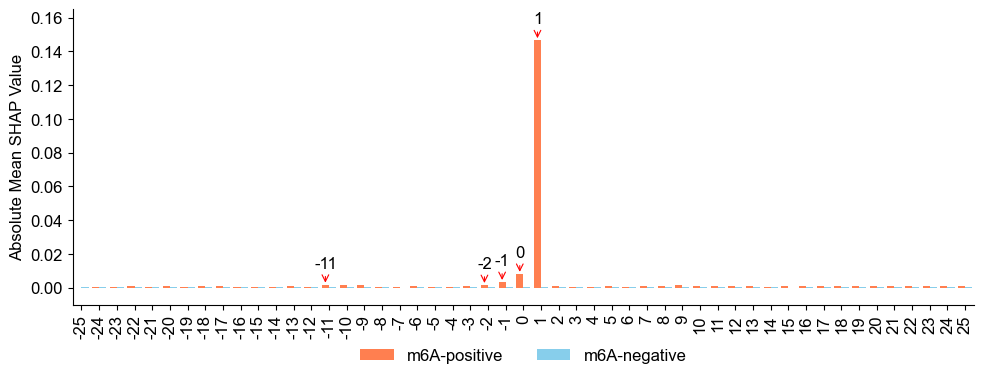

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
import matplotlib.font_manager as fm
import os

font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12
model_max_length = 803

with open('/work/home/rnasys/lidaoqian/LARMAR/output/test/fig/label1_test_500.pkl', 'rb') as f:
    label1_shap = pickle.load(f)
with open('/work/home/rnasys/lidaoqian/LARMAR/output/test/fig/label0_test_500.pkl', 'rb') as f:
    label0_shap = pickle.load(f)

def compute_mean_shap(shap_values_list, max_length):
    padded_shap_values = []
    for shap_vals in shap_values_list:
        padded = np.zeros(max_length)
        padded[:len(shap_vals)] = shap_vals
        padded_shap_values.append(padded)
    return np.mean(padded_shap_values, axis=0)

mean_shap_label_1 = compute_mean_shap(label1_shap, model_max_length)
mean_shap_label_0 = compute_mean_shap(label0_shap, model_max_length)

shap_label_1_trimmed = mean_shap_label_1[1:-1]  # 长度 801
shap_label_0_trimmed = mean_shap_label_0[1:-1]

# 提取区间 [375, 425]
start, end = 375, 426
x_abs = np.arange(start, end)  # 真实位置
x_rel = x_abs - 400            # 相对位置 (400 为中心点)

y1 = np.abs(shap_label_1_trimmed[start:end])
y0 = np.abs(shap_label_0_trimmed[start:end])
bar_width = 0.4

plt.figure(figsize=(10, 4))
plt.bar(x_rel - bar_width/2, y1, width=bar_width, color='coral', label='m6A-positive')
plt.bar(x_rel + bar_width/2, y0, width=bar_width, color='skyblue', label='m6A-negative')

plt.ylabel('Absolute Mean SHAP Value')
plt.xticks(
    ticks=x_rel,
    labels=[str(i) for i in x_rel],
    rotation=90,
    ha='center'
)
plt.xlim(x_rel[0] - 0.5, x_rel[-1] + 0.5)
plt.yticks(np.round(np.arange(0, 0.17, 0.02), 2))
plt.ylim(-0.01, 0.165)

# 找出 Label=1 区间内 Top5 绝对平均 SHAP 位置及对应值
top5_idx_relative = np.argsort(y1)[-5:]
top5_idx_relative = top5_idx_relative[np.argsort(top5_idx_relative)]  # 按顺序排序
top5_positions_abs = x_abs[top5_idx_relative]   # 真实位置
top5_positions_rel = x_rel[top5_idx_relative]   # 相对位置
top5_values = y1[top5_idx_relative]

# 用箭头和文字标注（标注真实位置，但横坐标是相对位置）
for pos_rel, val in zip(top5_positions_rel, top5_values):
    plt.annotate(
        f'{pos_rel}', 
        xy=(pos_rel - bar_width/2, val), 
        xytext=(pos_rel - bar_width/2, val + 0.01),
        fontsize=12,
        ha='center',
        arrowprops=dict(arrowstyle='->', color='red', lw=0.8, shrinkA=2, shrinkB=1.5)
    )


plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

os.makedirs("fig-1", exist_ok=True)
plt.tight_layout()
plt.savefig('fig-1/fig4B-1-2.png', dpi=600, bbox_inches='tight')
plt.show()


## 补充图

<Figure size 1000x200 with 0 Axes>

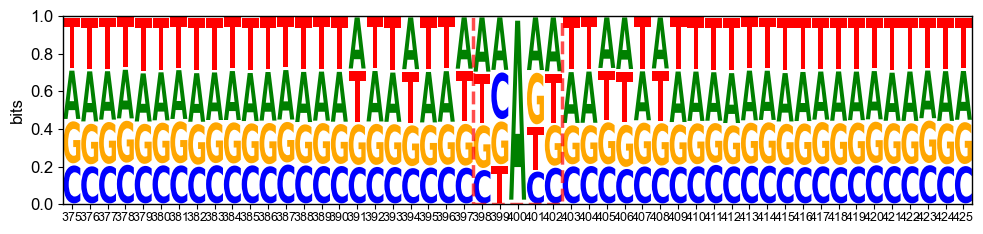

In [8]:
import logomaker
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

def read_sequences_from_csv(file_path, label_value):
    sequences = []
    seq_length = None
    df = pd.read_csv(file_path)
    if 'seq' not in df.columns or 'label' not in df.columns:
        raise ValueError("CSV file must contain 'seq' and 'label' columns.")
    
    # 过滤出label=0的序列
    df_filtered = df[df['label'] == label_value]
    
    for seq in df_filtered['seq']:
        if seq_length is None:
            seq_length = len(seq)
        elif len(seq) != seq_length:
            print(f"Skipping sequence with inconsistent length: {len(seq)}")
            continue
        sequences.append(seq)
    
    if not sequences:
        raise ValueError(f"No sequences found with consistent length and label={label_value}.")
    return sequences

def sequence_to_freq_matrix(sequences):
    if not sequences:
        raise ValueError("No sequences provided.")
    
    seq_length = len(sequences[0])  # 获取序列长度
    frequency_matrix = {i: {base: 0 for base in 'ACGT'} for i in range(seq_length)}
    
    for seq in sequences:
        if len(seq) != seq_length:
            raise ValueError(f"Sequence lengths are inconsistent. Expected length {seq_length}, but found {len(seq)}")
        for i, base in enumerate(seq):
            if base in frequency_matrix[i]:
                frequency_matrix[i][base] += 1
            #else:
                # 如果遇到非标准碱基，可以选择忽略或记录警告
                #print(f"Warning: Non-standard base '{base}' found at position {i}. Ignoring.")
    
    total_sequences = len(sequences)
    freq_data = []
    for i in range(seq_length):
        position_data = {base: frequency_matrix[i].get(base, 0) / total_sequences for base in 'ACGT'}
        freq_data.append(position_data)
    
    return pd.DataFrame(freq_data)

# 绘制sequence logo
def plot_sequence_logo(freq_matrix, savefig_path):
    seq_length = len(freq_matrix)
    center_start = (seq_length - 51) // 2
    center_end = center_start + 51
    center_matrix = freq_matrix.iloc[center_start:center_end]
    
    width_per_position = 0.05  # 每个位置3.5英寸宽
    plt.figure(figsize=(10, 2))  # 增加图像大小
    logo = logomaker.Logo(center_matrix, vpad=0.05)
    ax = plt.gca()  # 获取当前的Axes对象
    
    # 计算24-28位置的x坐标范围
    x_start = center_start+23  # 起始位置
    x_end = center_start+27     # 结束位置
    # 假设每个位置宽度相等，y范围基于logo的上下界（信息含量0到1）
    y_min = 0     # logo的最低点（信息含量0）
    y_max = 1.1   # logo的最高点（信息含量1以上留点余量）
    
    # 绘制虚线矩形框
    rect = Rectangle((x_start - 0.5, y_min),  # 左下角坐标（x_start - 0.5调整到字符中心）
                     x_end - x_start + 1,      # 宽度（包含28位置，+1调整）
                     y_max - y_min,            # 高度
                     linestyle='dashed',       # 虚线样式
                     edgecolor='red',          # 边框颜色
                     facecolor='none',         # 无填充
                     linewidth=2.5,            # 线宽
                     alpha=0.7)                # 透明度
    ax.add_patch(rect)
    
    logo.style_spines(spines=['left', 'bottom', 'right', 'top'], visible=True)  # 粗黑边框
    logo.style_xticks(fmt='%d')
    plt.tick_params(axis='x', labelsize=9, pad=2)
    plt.ylabel('bits')
    plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.1)
    plt.tight_layout()
    plt.savefig(savefig_path, dpi=600, bbox_inches='tight')
    plt.show()

# 主函数
def main(csv_file):
    savefig_path = 'fig-1/molm_m6a_logo_neg.png'
    sequences = read_sequences_from_csv(csv_file, 0)
    freq_matrix = sequence_to_freq_matrix(sequences)
    plot_sequence_logo(freq_matrix, savefig_path)

# 使用您的CSV文件路径
main('/work/home/rnasys/lidaoqian/M6A_Model/deepSRAMP/deepSRAMP/lamar-data-new/atlas-a/full/HEK293T_m6A-label-seq__merged.csv')

<Figure size 1000x400 with 0 Axes>

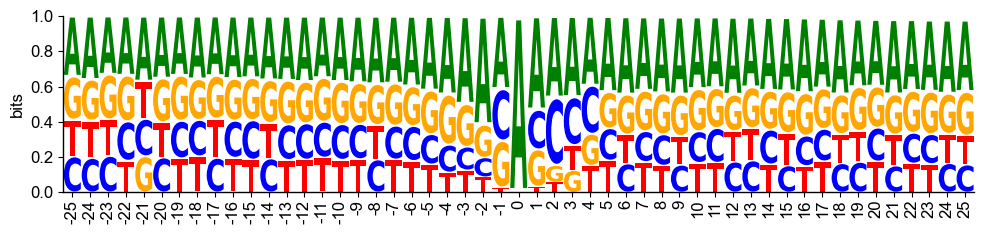

In [26]:
import logomaker
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import matplotlib.font_manager as fm
font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

def read_sequences_from_csv(file_path, label_value=1):
    sequences = []
    seq_length = None
    df = pd.read_csv(file_path)
    if 'seq' not in df.columns or 'label' not in df.columns:
        raise ValueError("CSV file must contain 'seq' and 'label' columns.")
    
    # 过滤出label=0的序列
    df_filtered = df[df['label'] == label_value]
    
    for seq in df_filtered['seq']:
        if seq_length is None:
            seq_length = len(seq)
        elif len(seq) != seq_length:
            print(f"Skipping sequence with inconsistent length: {len(seq)}")
            continue
        sequences.append(seq)
    
    if not sequences:
        raise ValueError(f"No sequences found with consistent length and label={label_value}.")
    return sequences

def sequence_to_freq_matrix(sequences):
    if not sequences:
        raise ValueError("No sequences provided.")
    
    seq_length = len(sequences[0])  # 获取序列长度
    frequency_matrix = {i: {base: 0 for base in 'ACGT'} for i in range(seq_length)}
    
    for seq in sequences:
        if len(seq) != seq_length:
            raise ValueError(f"Sequence lengths are inconsistent. Expected length {seq_length}, but found {len(seq)}")
        for i, base in enumerate(seq):
            if base in frequency_matrix[i]:
                frequency_matrix[i][base] += 1
            #else:
                # 如果遇到非标准碱基，可以选择忽略或记录警告
                #print(f"Warning: Non-standard base '{base}' found at position {i}. Ignoring.")
    
    total_sequences = len(sequences)
    freq_data = []
    for i in range(seq_length):
        position_data = {base: frequency_matrix[i].get(base, 0) / total_sequences for base in 'ACGT'}
        freq_data.append(position_data)
    
    return pd.DataFrame(freq_data)

# 绘制sequence logo
def plot_sequence_logo(freq_matrix, savefig_path):
    seq_length = len(freq_matrix)
    center_start = (seq_length - 51) // 2
    center_end = center_start + 51
    
    # === 确保列顺序正确且索引重置 ===
    center_matrix = freq_matrix.iloc[center_start:center_end][["A", "C", "G", "T"]].reset_index(drop=True)
    
    plt.figure(figsize=(10, 4))
    logo = logomaker.Logo(center_matrix, vpad=0.05)
    ax = plt.gca()

    # === 去掉上右边框 ===
    logo.style_spines(spines=['left', 'bottom'], visible=True)
    logo.style_spines(spines=['top', 'right'], visible=False)

    # === 设置 X 轴为 -25 到 +25 ===
    x_positions = np.arange(center_start, center_end)
    relative_positions = x_positions - (center_start + 25)
    ax.set_xticks(np.arange(0, 51, 1))
    ax.set_xticklabels(relative_positions, rotation=90)
    ax.set_xlim(-0.5, 50.5)

    # === 绘制红框标注位置 24–28 ===
    x_start = 23
    x_end = 27
    y_min = 0
    y_max = 1.1
    rect = Rectangle((x_start - 0.5, y_min),
                     x_end - x_start + 1,
                     y_max - y_min,
                     linestyle='dashed',
                     edgecolor='red',
                     facecolor='none',
                     linewidth=2.0,
                     alpha=0.7)
    #ax.add_patch(rect)

    plt.ylabel('bits')
    plt.tick_params(axis='x', labelsize=12, pad=2)
    plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.15)
    plt.tight_layout()
    plt.savefig(savefig_path, dpi=600, bbox_inches='tight')
    plt.show()



# 主函数
def main(csv_file):
    savefig_path = 'fig-1/CRMM1_miCLIP_m6a_logo_pos.png'
    sequences = read_sequences_from_csv(csv_file)
    freq_matrix = sequence_to_freq_matrix(sequences)
    plot_sequence_logo(freq_matrix, savefig_path)

# 使用您的CSV文件路径
main('/work/home/rnasys/lidaoqian/M6A_Model/deepSRAMP/deepSRAMP/lamar-data-new/atlas-a/full/CRMM1_miCLIP__merged.csv')

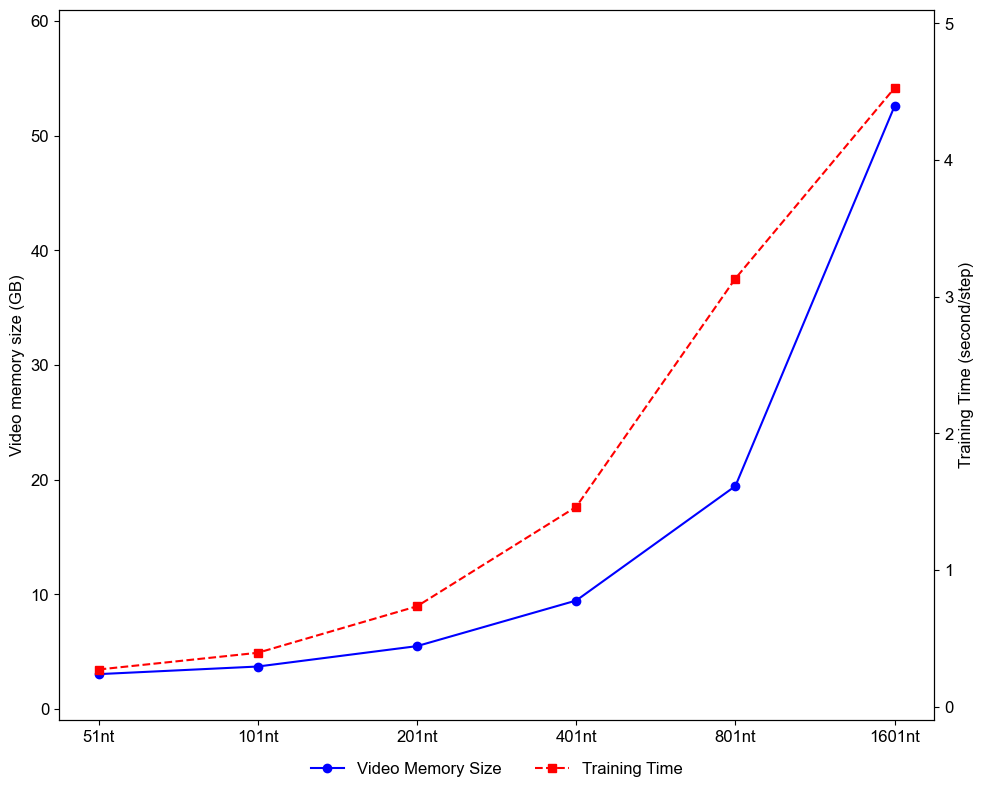

In [32]:
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.font_manager as fm

font_path = '/work/home/rnasys/lidaoqian/Fonts/arial.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

df = pd.read_csv('m6a-time.csv')
models = [m.replace('m6a-', '') + 'nt' for m in df['model']]
times = [t / 100 for t in df['time']]
gpu = [g / 1024 for g in df['gpu']]

# 单栏图尺寸（3.5 inch 宽）
fig, ax1 = plt.subplots(figsize=(10, 8))

# Plot ROC_AUC on left y-axis (red)
ax1.plot(models, gpu, marker='o', linestyle='-', color='blue', linewidth=1.5, label='Video Memory Size')
#ax1.set_xlabel('Model')
ax1.set_ylabel('Video memory size (GB)', color='black')
ax1.tick_params(axis='y', labelcolor='black')
ax1.set_ylim(0-1, 60+1 )

# Create right y-axis for Time (blue)
ax2 = ax1.twinx()
ax2.plot(models, times, marker='s', linestyle='--', color='red', linewidth=1.5, label='Training Time')
ax2.set_ylabel('Training Time (second/step)', color='black')
ax2.tick_params(axis='y', labelcolor='black')
ax2.set_ylim(0-0.1, 5+0.1)

# 图例
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles=lines1 + lines2, labels=labels1 + labels2,
           loc='lower center', bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=12, frameon=False)

fig.tight_layout()
plt.savefig('fig-1/figs1.png', dpi=600, bbox_inches='tight')  # 保存为高分辨率 PNG-1